<a href="https://colab.research.google.com/github/uday342100/Story/blob/main/ML_Project_CCE5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
import os
# Works whichever way the CSV is named on your machine
DATA_PATH = next(p for p in ["Traffic_dataset.csv", "traffic_dataset.csv", "Traffic dataset.csv"] if os.path.exists(p))
df = pd.read_csv("/content/Traffic dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1200, 9)


,Date,City,Area,Vehicle_Type,Vehicle_Count,Accidents,Traffic_Violations,Avg_Speed_kmph,Congestion_Level
0,2025-01-01,Pune,Hinjewadi,Auto,4396,4,44,41,Low
1,2025-01-02,Thane,Manpada,Truck,6708,6,228,31,Low
2,2025-01-03,Mumbai,Lower Parel,Car,12940,3,98,39,High
3,2025-01-04,Thane,Kasarvadavali,Bus,5062,1,245,44,Low
4,2025-01-05,Nashik,College Road,Bus,13794,3,120,44,High


In [9]:
# Display column names
print("Column names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
display(df.describe(include="all"))

Column names:
['Date', 'City', 'Area', 'Vehicle_Type', 'Vehicle_Count', 'Accidents', 'Traffic_Violations', 'Avg_Speed_kmph', 'Congestion_Level']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Date                1200 non-null   object
 1   City                1200 non-null   object
 2   Area                1200 non-null   object
 3   Vehicle_Type        1200 non-null   object
 4   Vehicle_Count       1200 non-null   int64 
 5   Accidents           1200 non-null   int64 
 6   Traffic_Violations  1200 non-null   int64 
 7   Avg_Speed_kmph      1200 non-null   int64 
 8   Congestion_Level    1200 non-null   object
dtypes: int64(4), object(5)
memory usage: 84.5+ KB

Missing values:
Date                  0
City                  0
Area                  0
Vehicle_Type          0
Vehicle_Count         0
Accidents  

,Date,City,Area,Vehicle_Type,Vehicle_Count,Accidents,Traffic_Violations,Avg_Speed_kmph,Congestion_Level
count,1200,1200,1200,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200
unique,365,5,25,5,NaN,NaN,NaN,NaN,3
top,2025-01-01,Nashik,College Road,Car,NaN,NaN,NaN,NaN,High
freq,4,262,61,258,NaN,NaN,NaN,NaN,449
mean,NaN,NaN,NaN,NaN,9585.048333,4.010833,171.765000,40.570833,NaN
std,NaN,NaN,NaN,NaN,3194.484195,2.545476,76.657594,11.804636,NaN
min,NaN,NaN,NaN,NaN,4008.000000,0.000000,40.000000,20.000000,NaN
25%,NaN,NaN,NaN,NaN,6758.250000,2.000000,104.750000,30.000000,NaN
50%,NaN,NaN,NaN,NaN,9892.500000,4.000000,175.000000,41.000000,NaN
75%,NaN,NaN,NaN,NaN,12237.750000,6.000000,239.000000,51.000000,NaN


In [10]:
print("Cities in the dataset:")
print(df["City"].unique())

print("\nNumber of records per city:")
print(df["City"].value_counts())

Cities in the dataset:
['Pune' 'Thane' 'Mumbai' 'Nashik' 'Nagpur']

Number of records per city:
City
Nashik    262
Thane     242
Pune      234
Mumbai    234
Nagpur    228
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

Before clustering, we look at how each variable is distributed, whether any variables are related, and whether the dataset has outliers or missing values.

In [11]:
E_INK, E_RED, E_GREEN, E_TAN = "#1B2333", "#B5402F", "#4A6B45", "#C8956C"
num_cols = ["Vehicle_Count", "Avg_Speed_kmph", "Accidents", "Traffic_Violations"]
df["Date"] = pd.to_datetime(df["Date"])
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Cities:", df["City"].nunique(), "| Areas:", df["Area"].nunique(), "| Vehicle types:", df["Vehicle_Type"].nunique())

# Outlier check with the 1.5 x IQR rule, and skewness
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    rows.append({"Feature": c, "Outliers (IQR rule)": int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()),
                 "Skewness": round(df[c].skew(), 2)})
display(pd.DataFrame(rows))

Date range: 2025-01-01 to 2025-12-31
Cities: 5 | Areas: 25 | Vehicle types: 5


,Feature,Outliers (IQR rule),Skewness
0,Vehicle_Count,0,-0.04
1,Avg_Speed_kmph,0,-0.04
2,Accidents,0,-0.02
3,Traffic_Violations,0,-0.03


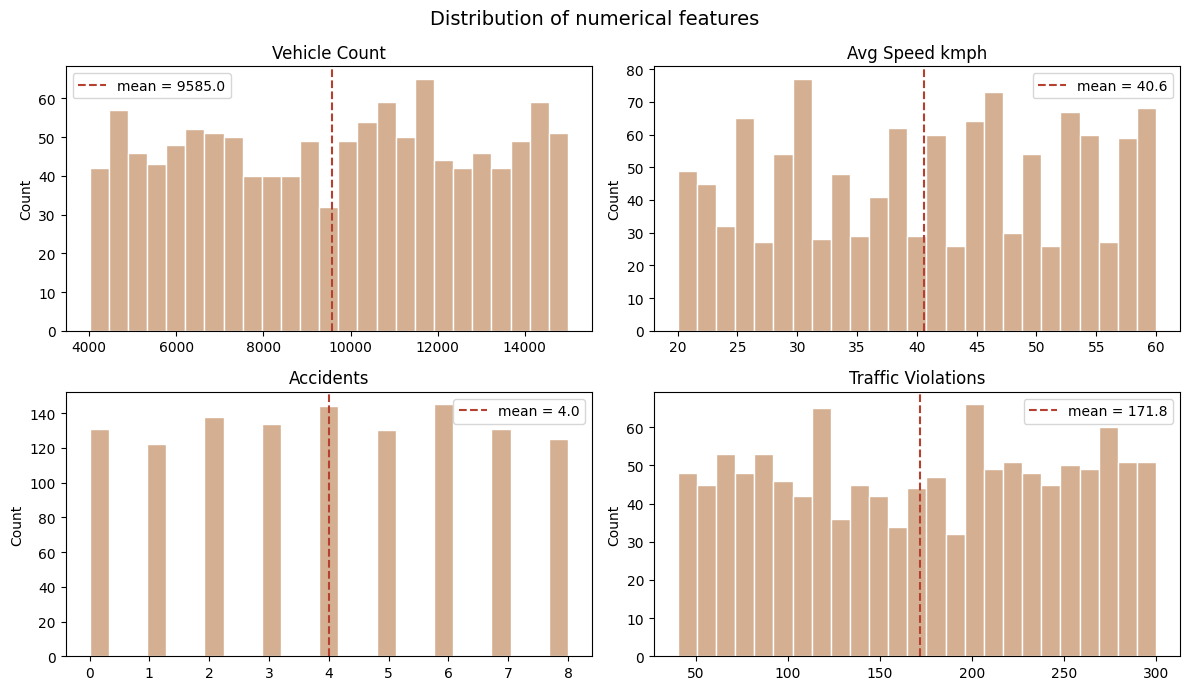

In [12]:
# Distribution of each numerical feature
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=25, color=E_TAN, edgecolor="white", ax=ax)
    ax.axvline(df[c].mean(), color=E_RED, lw=1.5, ls="--", label=f"mean = {df[c].mean():.1f}")
    ax.set_title(c.replace("_", " ")); ax.set_xlabel(""); ax.legend()
plt.suptitle("Distribution of numerical features", fontsize=14)
plt.tight_layout(); plt.show()

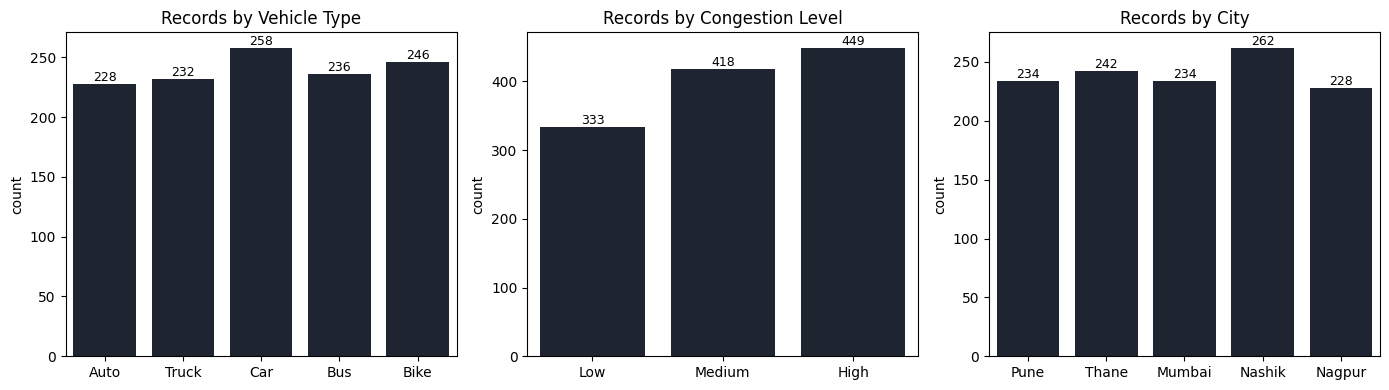

In [13]:
# Categorical features
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c, order in zip(axes, ["Vehicle_Type", "Congestion_Level", "City"],
                        [None, ["Low", "Medium", "High"], None]):
    sns.countplot(data=df, x=c, order=order, color=E_INK, ax=ax)
    ax.set_title(f"Records by {c.replace('_', ' ')}"); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

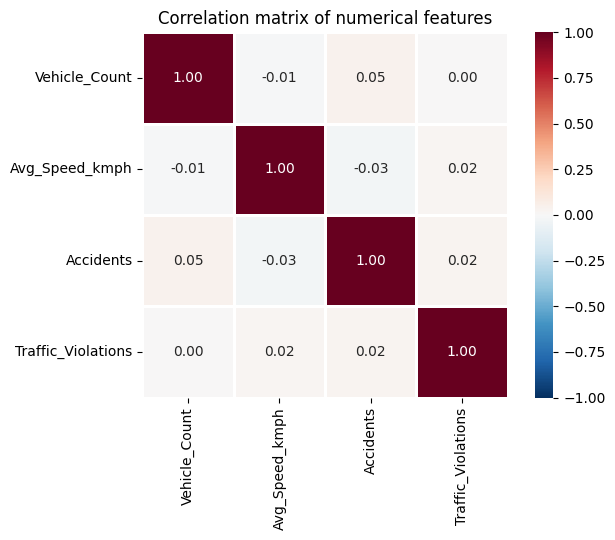

In [14]:
# Correlation between the numerical features
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=1, square=True)
plt.title("Correlation matrix of numerical features")
plt.tight_layout(); plt.show()

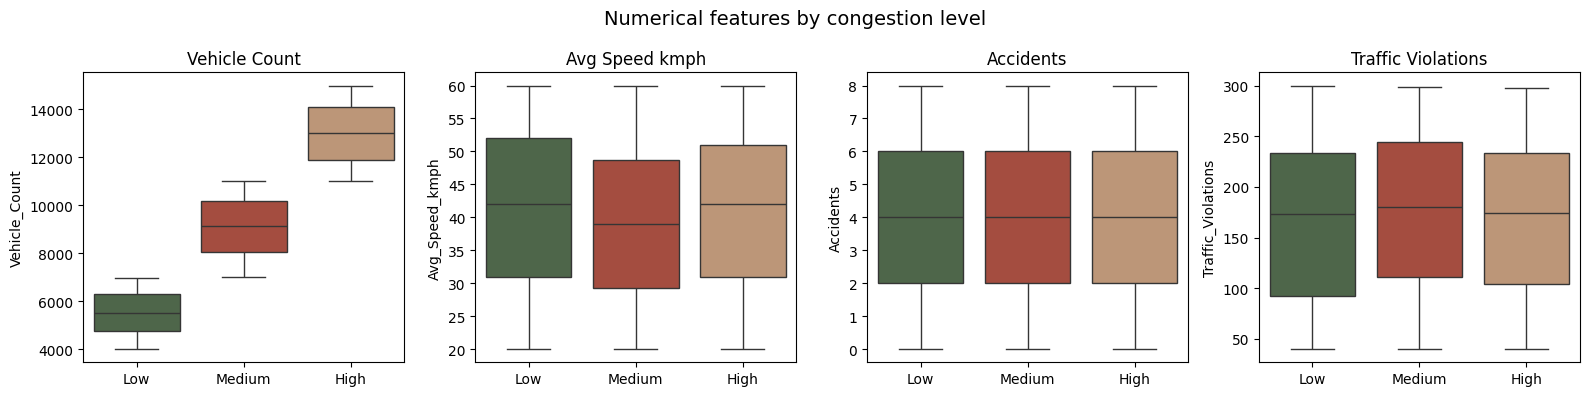

,min,max,mean
Congestion_Level,,,
Low,4008,6991,5550.0
Medium,7011,10999,9122.0
High,11003,14993,13008.0


In [15]:
# How do the features differ across congestion levels?
order = ["Low", "Medium", "High"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="Congestion_Level", y=c, order=order, hue="Congestion_Level", palette=[E_GREEN, E_TAN, E_RED], legend=False, ax=ax)
    ax.set_title(c.replace("_", " ")); ax.set_xlabel("")
plt.suptitle("Numerical features by congestion level", fontsize=14)
plt.tight_layout(); plt.show()

display(df.groupby("Congestion_Level")["Vehicle_Count"].agg(["min", "max", "mean"]).loc[order].round(0))

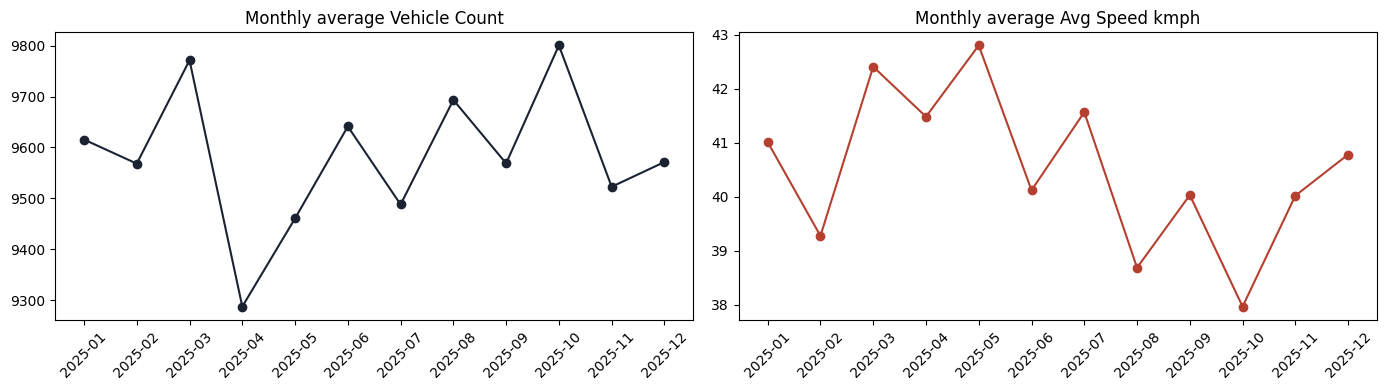

In [16]:
# Monthly trend over 2025
monthly = df.groupby(df["Date"].dt.to_period("M"))[["Vehicle_Count", "Avg_Speed_kmph"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c, col in zip(axes, ["Vehicle_Count", "Avg_Speed_kmph"], [E_INK, E_RED]):
    ax.plot(monthly.index.astype(str), monthly[c], marker="o", color=col)
    ax.set_title(f"Monthly average {c.replace('_', ' ')}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### EDA findings

* The dataset is clean: 1,200 rows, no missing values, no duplicates, no outliers by the IQR rule.
* All four numerical features are spread almost evenly across their range (skewness close to 0), so no transformation is needed.
* **Vehicle count is the only feature linked to congestion.** Congestion is Low below about 7,000 vehicles, Medium from 7,000 to 11,000 and High above 11,000.
* Speed, accidents and violations are almost uncorrelated with each other and with vehicle count (all |r| < 0.06). Clustering on them cannot be expected to give sharply separated groups.
* Cities, areas and vehicle types are balanced, and the monthly trend is flat apart from random variation.

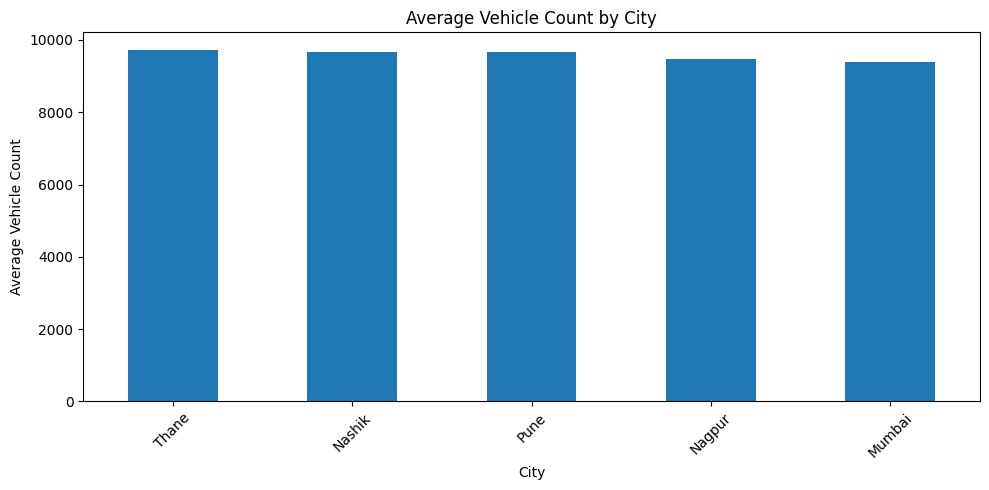

In [17]:
city_traffic = (
    df.groupby("City")["Vehicle_Count"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

city_traffic.plot(kind="bar")

plt.title("Average Vehicle Count by City")
plt.xlabel("City")
plt.ylabel("Average Vehicle Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

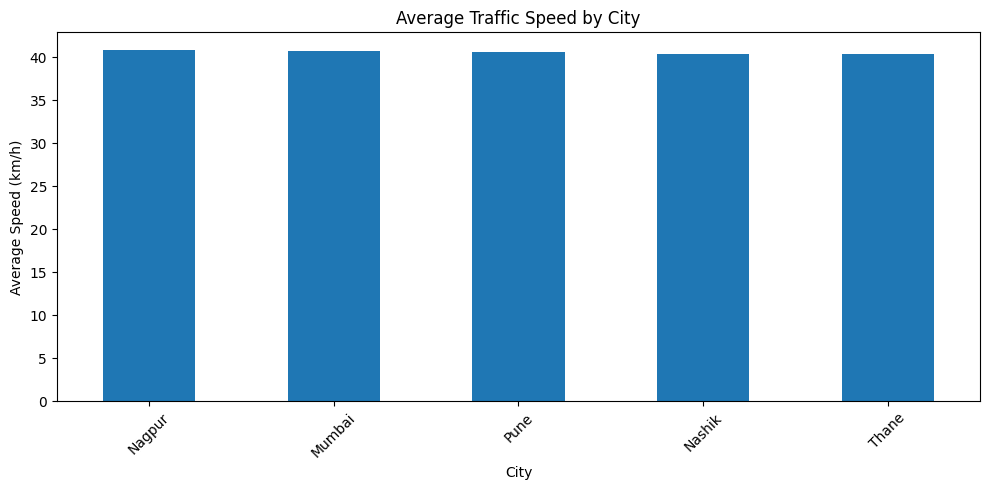

In [18]:
city_speed = (
    df.groupby("City")["Avg_Speed_kmph"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

city_speed.plot(kind="bar")

plt.title("Average Traffic Speed by City")
plt.xlabel("City")
plt.ylabel("Average Speed (km/h)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

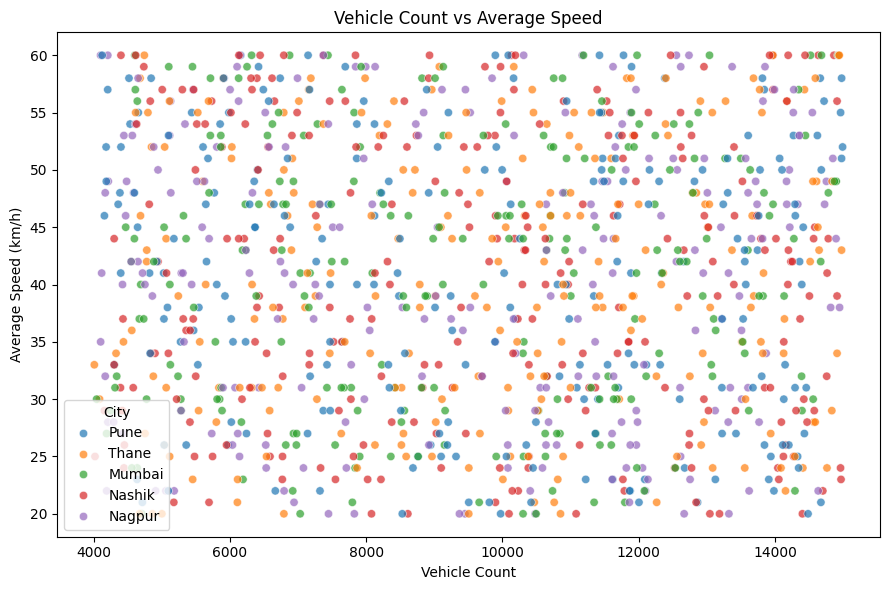

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Vehicle_Count",
    y="Avg_Speed_kmph",
    hue="City",
    alpha=0.7
)

plt.title("Vehicle Count vs Average Speed")
plt.xlabel("Vehicle Count")
plt.ylabel("Average Speed (km/h)")
plt.tight_layout()
plt.show()

In [20]:
# Select numerical features for clustering
features = [
    "Vehicle_Count",
    "Avg_Speed_kmph",
    "Accidents",
    "Traffic_Violations"
]

# Create a separate DataFrame for clustering
X = df[features].copy()

# Keep city information for later analysis
city_labels = df["City"].copy()

print("Selected features:")
display(X.head())

print("\nFeature dimensions:", X.shape)

Selected features:


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
0,4396,41,4,44
1,6708,31,6,228
2,12940,39,3,98
3,5062,44,1,245
4,13794,44,3,120



Feature dimensions: (1200, 4)


In [21]:
print("Missing values in selected features:")
print(X.isnull().sum())

Missing values in selected features:
Vehicle_Count         0
Avg_Speed_kmph        0
Accidents             0
Traffic_Violations    0
dtype: int64


In [22]:
print("Negative values in each feature:")
print((X < 0).sum())

print("\nFeature summary:")
display(X.describe())

Negative values in each feature:
Vehicle_Count         0
Avg_Speed_kmph        0
Accidents             0
Traffic_Violations    0
dtype: int64

Feature summary:


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,9585.048333,40.570833,4.010833,171.765000
std,3194.484195,11.804636,2.545476,76.657594
min,4008.000000,20.000000,0.000000,40.000000
25%,6758.250000,30.000000,2.000000,104.750000
50%,9892.500000,41.000000,4.000000,175.000000
75%,12237.750000,51.000000,6.000000,239.000000
max,14993.000000,60.000000,8.000000,300.000000


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Standardization completed successfully!")
display(X_scaled.head())

Standardization completed successfully!


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
0,-1.625055,0.036371,-0.004258,-1.667392
1,-0.901006,-0.811107,0.781778,0.733893
2,1.050671,-0.133125,-0.397275,-0.962667
3,-1.416483,0.290614,-1.183310,0.955750
4,1.318118,0.290614,-0.397275,-0.675557


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("K-Means imported successfully!")

K-Means imported successfully!


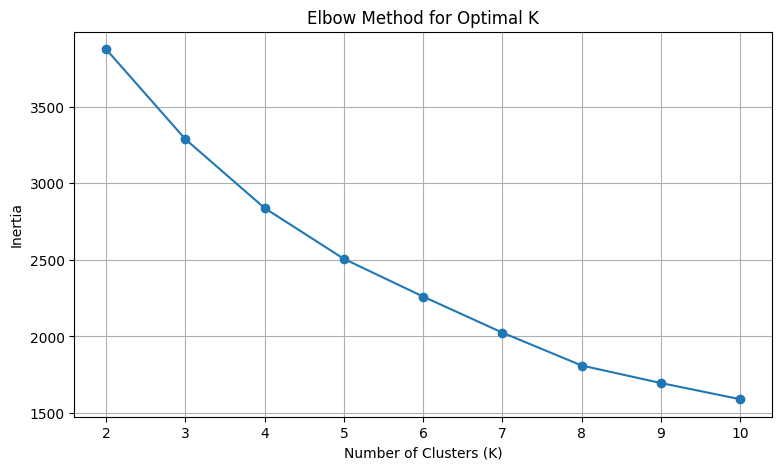

In [25]:
inertia_values = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(9, 5))
plt.plot(list(K_range), inertia_values, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

K = 2, Silhouette Score = 0.1905
K = 3, Silhouette Score = 0.1841
K = 4, Silhouette Score = 0.1997
K = 5, Silhouette Score = 0.2014
K = 6, Silhouette Score = 0.2041
K = 7, Silhouette Score = 0.2197
K = 8, Silhouette Score = 0.2376
K = 9, Silhouette Score = 0.2298
K = 10, Silhouette Score = 0.2253


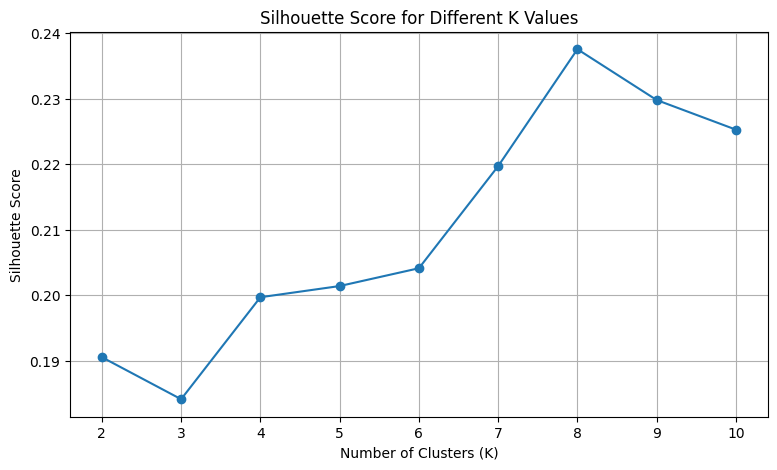

In [26]:
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(9, 5))
plt.plot(list(K_range), silhouette_scores, marker="o")

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Train the K-Means model
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

# Assign cluster labels
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Evaluate the model
score = silhouette_score(X_scaled, df["Cluster"])

print("K-Means model trained successfully!")
print("Number of clusters:", kmeans.n_clusters)
print("Silhouette Score:", round(score, 4))

print("\nCluster sizes:")
print(df["Cluster"].value_counts().sort_index())

K-Means model trained successfully!
Number of clusters: 8
Silhouette Score: 0.2376

Cluster sizes:
Cluster
0    146
1    162
2    152
3    139
4    150
5    160
6    154
7    137
Name: count, dtype: int64


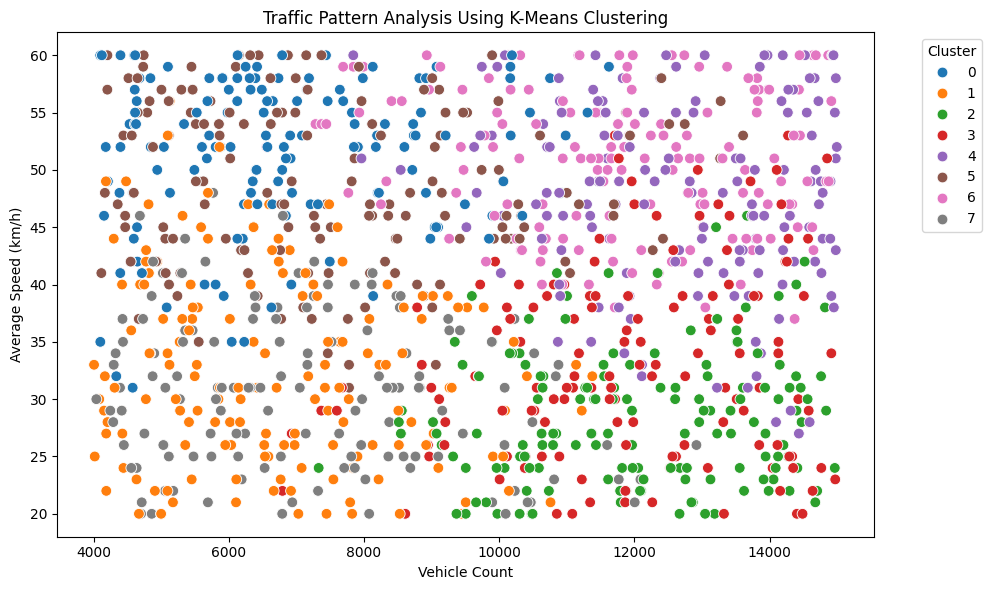

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Vehicle_Count",
    y="Avg_Speed_kmph",
    hue="Cluster",
    palette="tab10",
    s=60
)

plt.title("Traffic Pattern Analysis Using K-Means Clustering")
plt.xlabel("Vehicle Count")
plt.ylabel("Average Speed (km/h)")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [29]:
cluster_summary = df.groupby("Cluster")[
    [
        "Vehicle_Count",
        "Avg_Speed_kmph",
        "Accidents",
        "Traffic_Violations"
    ]
].mean().round(2)

print("Average characteristics of each cluster:")
display(cluster_summary)

Average characteristics of each cluster:


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
Cluster,,,,
0,6821.78,51.35,5.07,103.64
1,6755.63,32.40,5.87,229.43
2,12009.20,28.66,3.19,228.73
3,11959.19,33.09,6.40,103.45
4,12735.53,47.64,1.85,121.39
5,7557.66,48.79,1.59,236.13
6,11812.87,50.85,6.05,228.40
7,7191.27,30.66,2.07,98.61


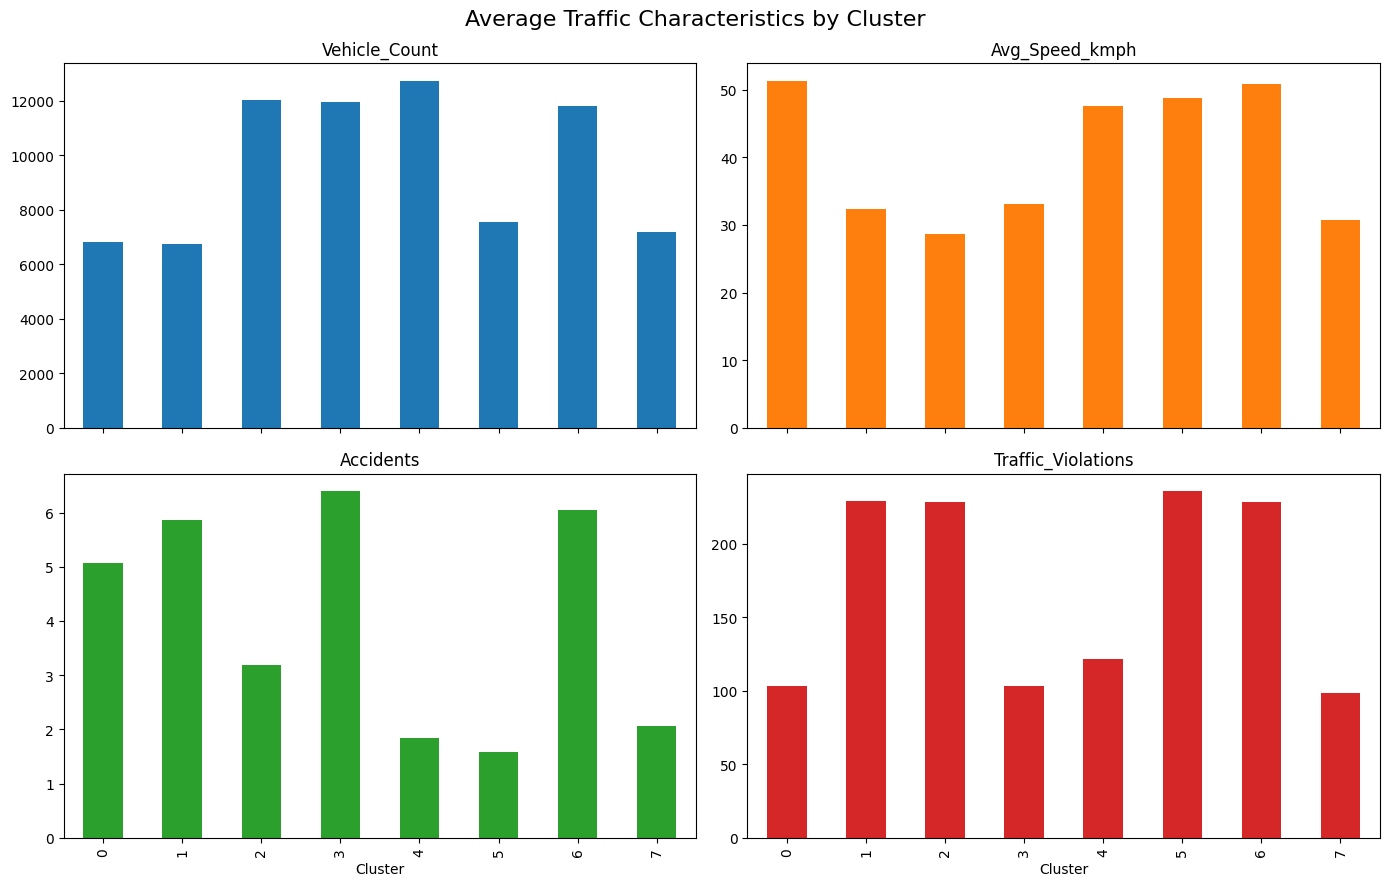

In [30]:
cluster_summary.plot(
    kind="bar",
    subplots=True,
    layout=(2, 2),
    figsize=(14, 9),
    legend=False,
    sharex=True
)

plt.suptitle("Average Traffic Characteristics by Cluster", fontsize=16)
plt.tight_layout()
plt.show()

In [31]:
# Calculate the mean of each feature for every cluster
cluster_summary = df.groupby("Cluster")[
    [
        "Vehicle_Count",
        "Avg_Speed_kmph",
        "Accidents",
        "Traffic_Violations"
    ]
].mean().round(2)

# Sort clusters by average vehicle count
cluster_summary = cluster_summary.sort_values(
    by="Vehicle_Count",
    ascending=False
)

display(cluster_summary)

,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
Cluster,,,,
4,12735.53,47.64,1.85,121.39
2,12009.20,28.66,3.19,228.73
3,11959.19,33.09,6.40,103.45
6,11812.87,50.85,6.05,228.40
5,7557.66,48.79,1.59,236.13
7,7191.27,30.66,2.07,98.61
0,6821.78,51.35,5.07,103.64
1,6755.63,32.40,5.87,229.43


In [32]:
# Count observations for each city and cluster
city_cluster_counts = pd.crosstab(
    df["City"],
    df["Cluster"]
)

display(city_cluster_counts)

Cluster,0,1,2,3,4,5,6,7
City,,,,,,,,
Mumbai,28,32,34,18,27,39,29,27
Nagpur,27,31,32,26,27,29,33,23
Nashik,29,37,30,36,35,31,30,34
Pune,31,29,35,23,33,32,25,26
Thane,31,33,21,36,28,29,37,27


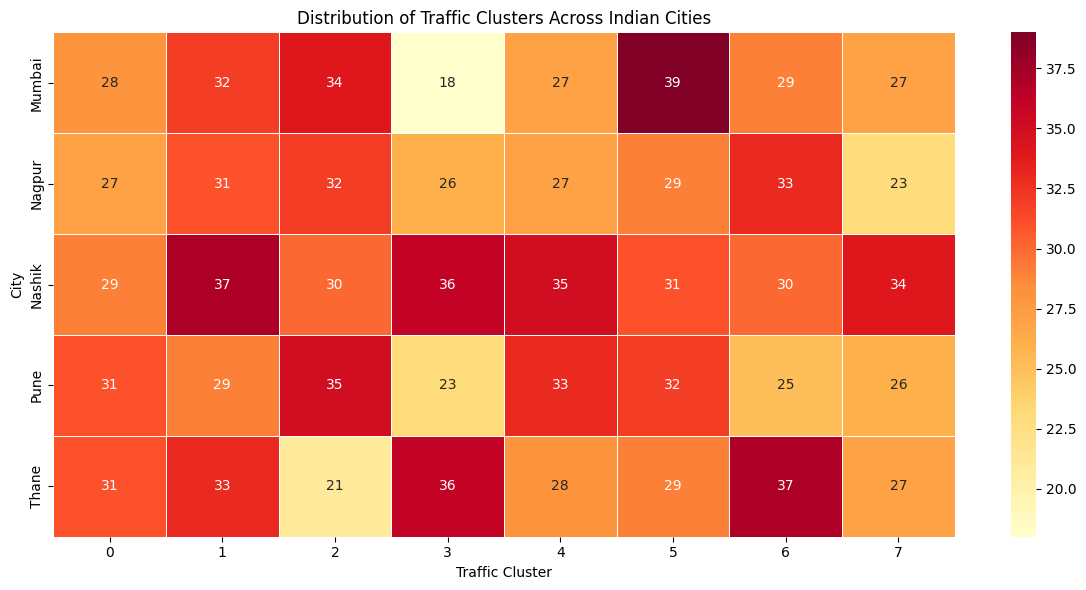

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

city_cluster_counts = pd.crosstab(
    df["City"],
    df["Cluster"]
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    city_cluster_counts,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Distribution of Traffic Clusters Across Indian Cities")
plt.xlabel("Traffic Cluster")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in [3, 4, 5, 8]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(
            silhouette_score(X_scaled, labels), 4
        )
    })

results_df = pd.DataFrame(results)

display(results_df)

,K,Inertia,Silhouette Score
0,3,3288.11,0.1841
1,4,2838.41,0.1997
2,5,2506.81,0.2014
3,8,1810.48,0.2376


In [35]:
# Calculate average characteristics of each cluster
cluster_summary = df.groupby("Cluster")[
    [
        "Vehicle_Count",
        "Avg_Speed_kmph",
        "Accidents",
        "Traffic_Violations"
    ]
].mean()

# Assign descriptive names based on the cluster averages
cluster_names = {
    0: "Lower Volume - Higher Speed",
    1: "Lower Volume - Lower Speed",
    2: "High Volume - Lower Speed",
    3: "High Volume - Moderate Speed",
    4: "High Volume - Higher Speed",
    5: "Moderate Volume - Higher Speed",
    6: "High Volume - Higher Speed",
    7: "Lower Volume - Lower Speed"
}

df["Traffic_Pattern"] = df["Cluster"].map(cluster_names)

print("Traffic pattern names assigned successfully!")

display(
    df[
        ["City", "Vehicle_Count", "Avg_Speed_kmph",
         "Accidents", "Traffic_Violations",
         "Cluster", "Traffic_Pattern"]
    ].head(10)
)

Traffic pattern names assigned successfully!


,City,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations,Cluster,Traffic_Pattern
0,Pune,4396,41,4,44,0,Lower Volume - Higher Speed
1,Thane,6708,31,6,228,1,Lower Volume - Lower Speed
2,Mumbai,12940,39,3,98,4,High Volume - Higher Speed
3,Thane,5062,44,1,245,5,Moderate Volume - Higher Speed
4,Nashik,13794,44,3,120,4,High Volume - Higher Speed
5,Pune,8686,24,5,63,7,Lower Volume - Lower Speed
6,Nagpur,14218,45,3,87,4,High Volume - Higher Speed
7,Nashik,11530,56,2,195,4,High Volume - Higher Speed
8,Nagpur,8017,38,0,242,5,Moderate Volume - Higher Speed
9,Nagpur,14729,47,0,44,4,High Volume - Higher Speed


In [36]:
city_summary = df.groupby("City")[
    [
        "Vehicle_Count",
        "Avg_Speed_kmph",
        "Accidents",
        "Traffic_Violations"
    ]
].mean().round(2)

display(city_summary)

,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
City,,,,
Mumbai,9393.91,40.71,3.78,182.47
Nagpur,9462.91,40.84,4.06,176.23
Nashik,9676.60,40.40,4.14,166.96
Pune,9651.31,40.61,3.81,164.97
Thane,9721.75,40.33,4.24,168.98


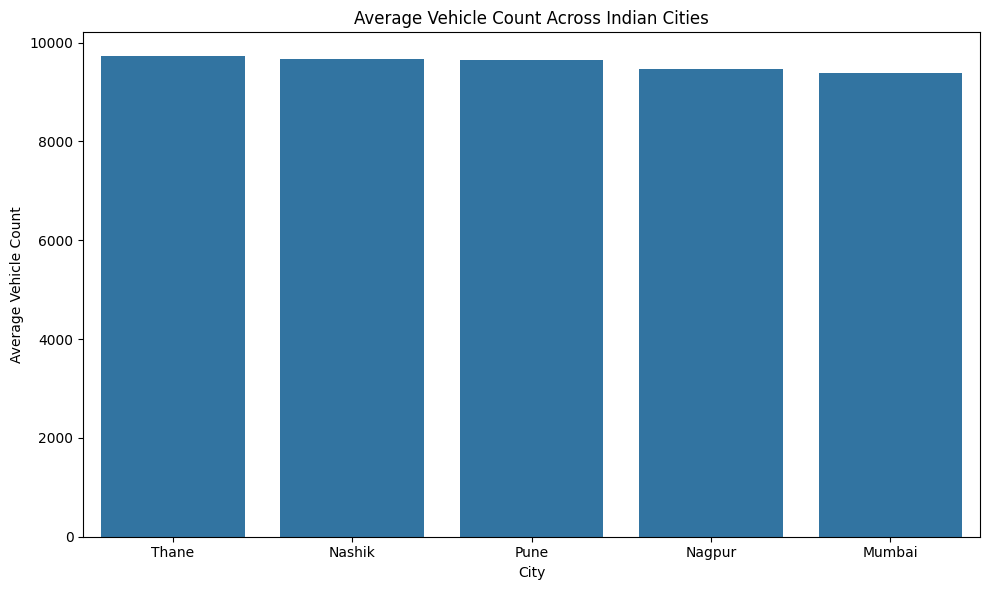

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

city_summary = df.groupby("City")[
    [
        "Vehicle_Count",
        "Avg_Speed_kmph",
        "Accidents",
        "Traffic_Violations"
    ]
].mean()

# Sort cities by average vehicle count
city_summary = city_summary.sort_values(
    by="Vehicle_Count",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_summary.index,
    y=city_summary["Vehicle_Count"]
)

plt.title("Average Vehicle Count Across Indian Cities")
plt.xlabel("City")
plt.ylabel("Average Vehicle Count")
plt.tight_layout()
plt.show()

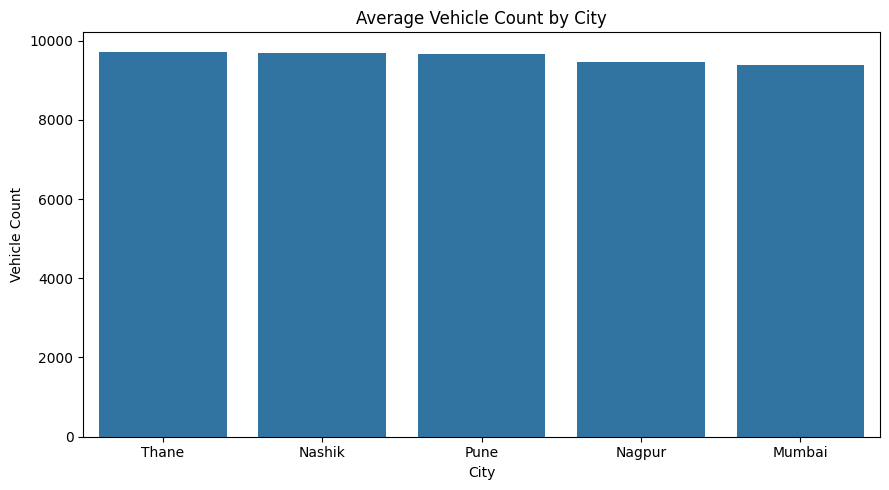

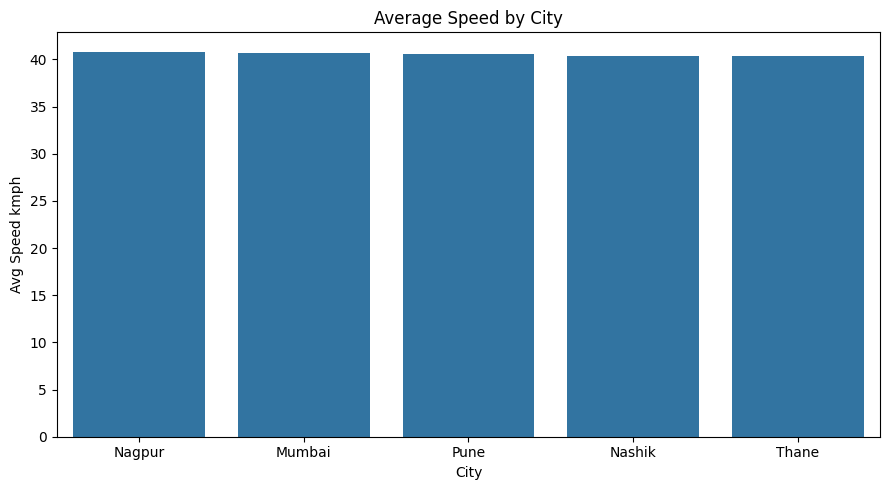

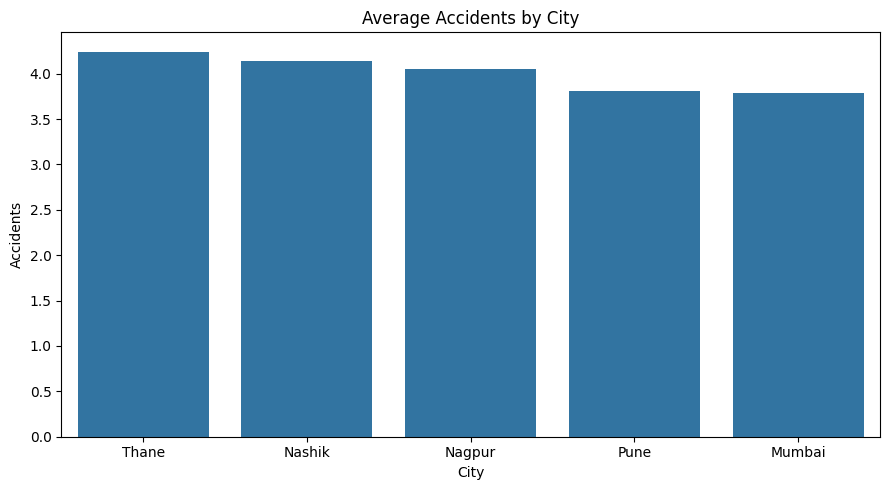

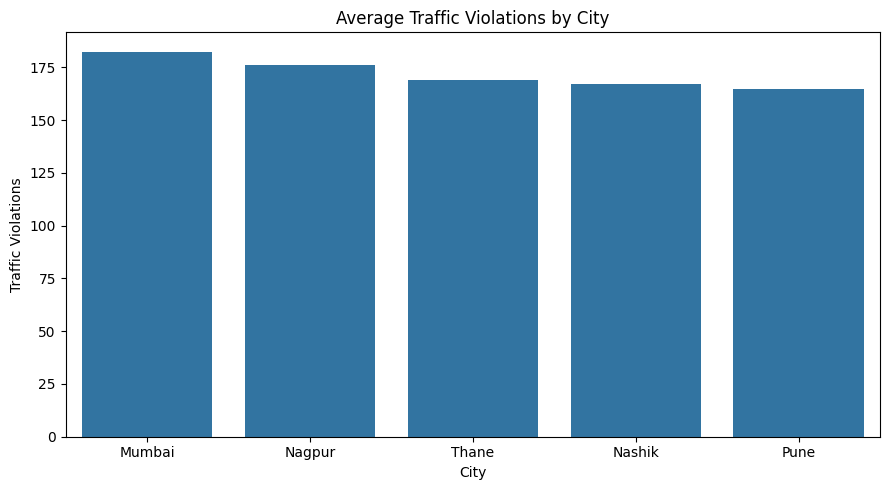

In [38]:
metrics = [
    "Vehicle_Count",
    "Avg_Speed_kmph",
    "Accidents",
    "Traffic_Violations"
]

titles = [
    "Average Vehicle Count by City",
    "Average Speed by City",
    "Average Accidents by City",
    "Average Traffic Violations by City"
]

for metric, title in zip(metrics, titles):
    plt.figure(figsize=(9, 5))

    city_data = city_summary[metric].sort_values(
        ascending=False
    )

    sns.barplot(
        x=city_data.index,
        y=city_data.values
    )

    plt.title(title)
    plt.xlabel("City")
    plt.ylabel(metric.replace("_", " "))
    plt.tight_layout()
    plt.show()

## Presentation figures

The cells below rebuild the seven result graphs used in the project deck (plus an extra cluster scatter), in the deck's colour palette, and save them to `deck_figures/`. Each figure is exported at the exact size of its frame in the slides. The last cell re-checks every number quoted in the deck against the data.

In [39]:
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

INK, RED, GREEN, TAN = "#1B2333", "#B5402F", "#4A6B45", "#C8956C"
MUTED, GRID, SURF = "#6B6A66", "#E4DCCB", "#FBF7EE"
SEQ = LinearSegmentedColormap.from_list("deck_seq", [SURF, "#EBC9B8", "#D4876F", RED])     # magnitude (one hue)
DIV = LinearSegmentedColormap.from_list("deck_div", ["#2F4B6E", "#9DB1C9", "#F3EEE4", "#E0A18F", RED])  # below / above average
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

plt.rcdefaults()
plt.rcParams.update({
    "font.size": 8,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
OUT = "deck_figures"; os.makedirs(OUT, exist_ok=True)

def new_fig(w_px, h_px):
    """Figure whose pixel size equals the frame size on a 1920 x 1080 slide."""
    return plt.subplots(figsize=(w_px / 100, h_px / 100), dpi=300)

def save(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=300); plt.show(); plt.close(fig)

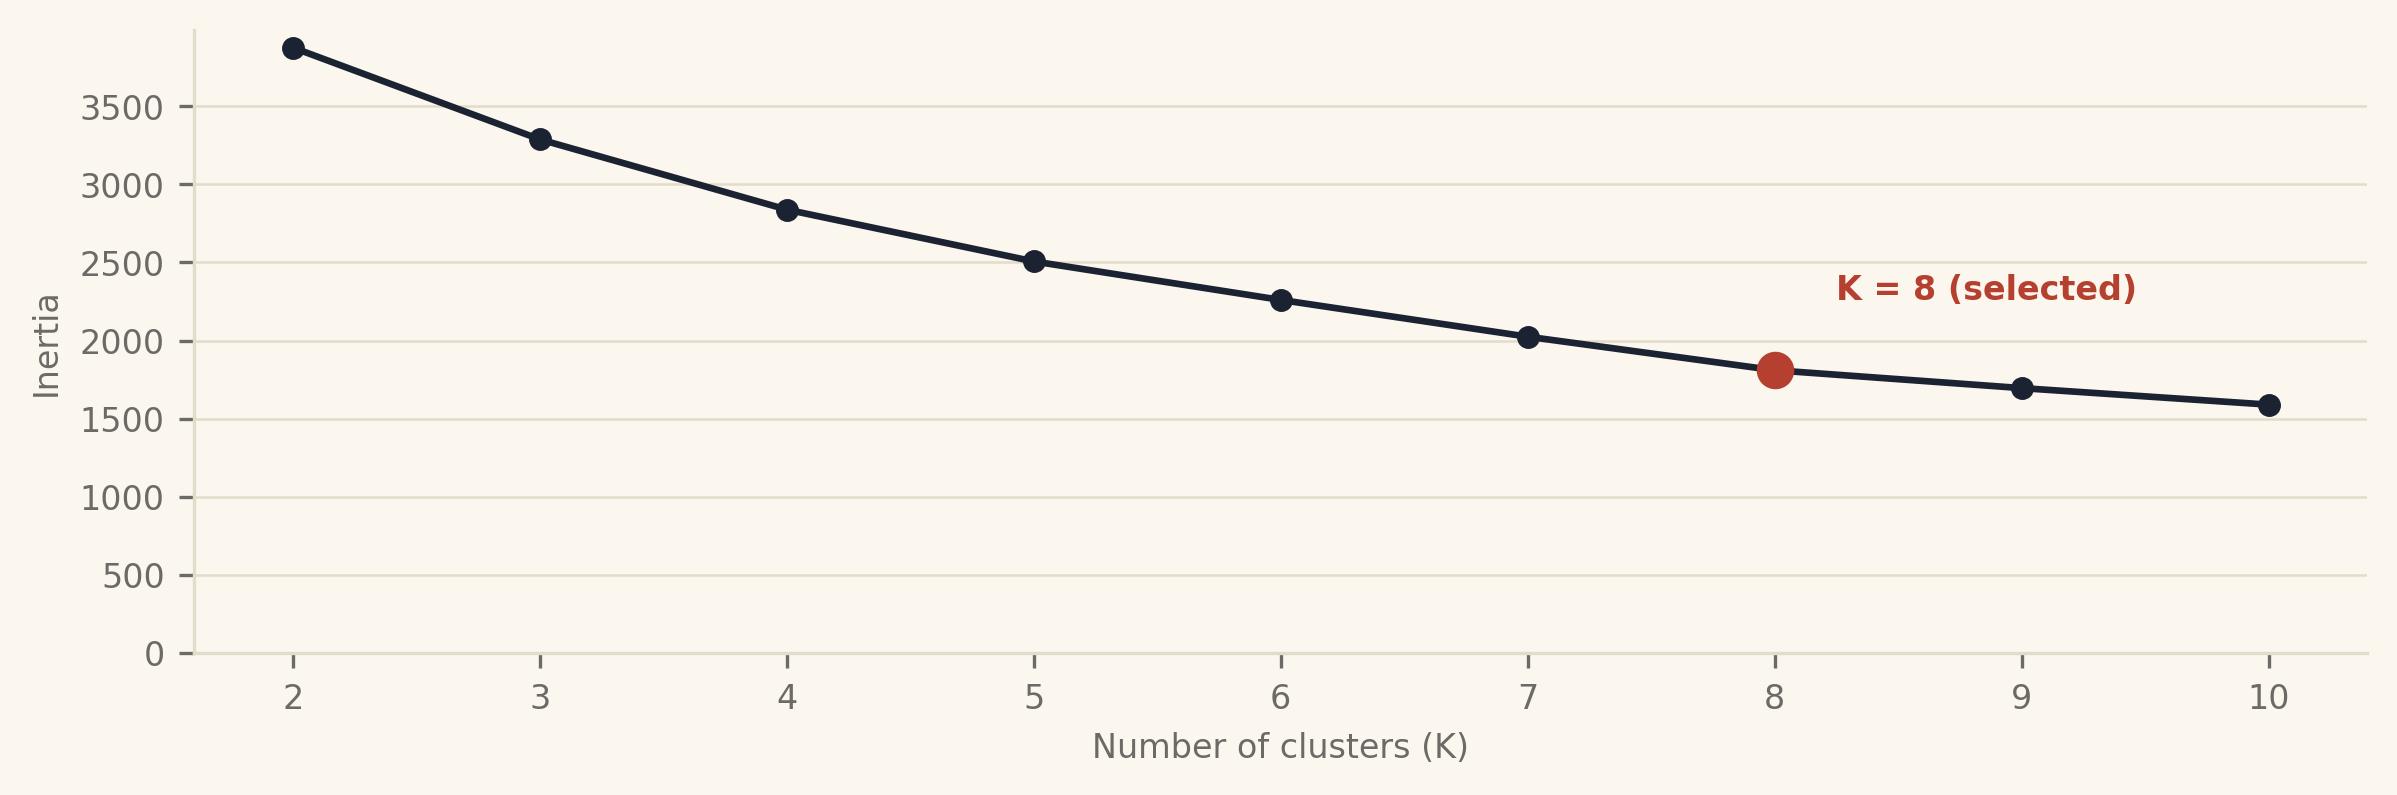

In [40]:
# 01 - Elbow method (slide 6)
fig, ax = new_fig(788, 254)
ks = list(K_range)
ax.plot(ks, inertia_values, color=INK, lw=1.6, marker="o", ms=4.5, mfc=INK)
ax.plot([8], [inertia_values[ks.index(8)]], marker="o", ms=8, color=RED, zorder=5)
ax.annotate("K = 8 (selected)", (8, inertia_values[ks.index(8)]), xytext=(8.25, inertia_values[ks.index(8)] + 450),
            color=RED, fontsize=8, fontweight="bold")
ax.set_xticks(ks); ax.set_xlabel("Number of clusters (K)"); ax.set_ylabel("Inertia"); ax.grid(axis="x", visible=False)
ax.set_ylim(bottom=0)
fig.tight_layout(pad=0.4); save(fig, "01_elbow_method.png")

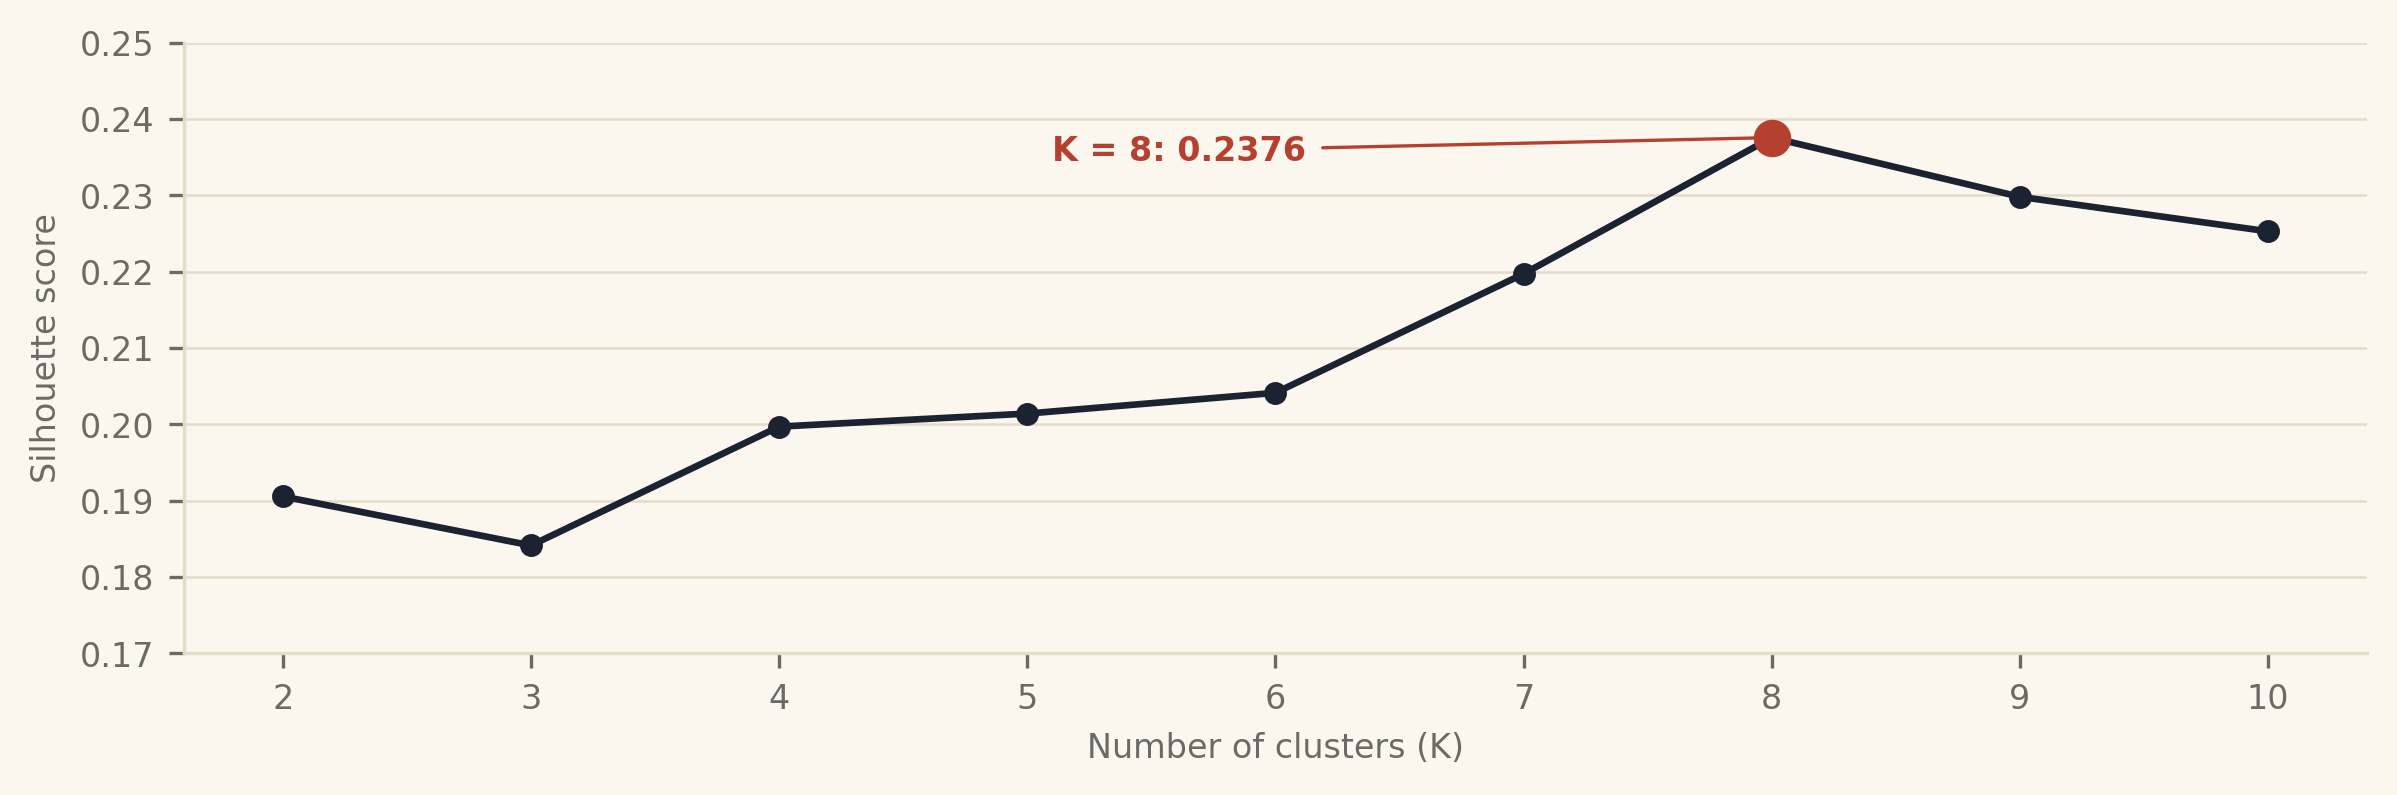

In [41]:
# 02 - Silhouette scores (slide 6)
fig, ax = new_fig(788, 254)
ax.plot(ks, silhouette_scores, color=INK, lw=1.6, marker="o", ms=4.5, mfc=INK)
i8 = ks.index(8)
ax.plot([8], [silhouette_scores[i8]], marker="o", ms=8, color=RED, zorder=5)
ax.annotate(f"K = 8: {silhouette_scores[i8]:.4f}", (8, silhouette_scores[i8]), xytext=(5.1, silhouette_scores[i8] - 0.003),
            color=RED, fontsize=8, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RED, lw=0.8))
ax.set_xticks(ks); ax.set_xlabel("Number of clusters (K)"); ax.set_ylabel("Silhouette score"); ax.grid(axis="x", visible=False)
ax.set_ylim(0.17, 0.25)
fig.tight_layout(pad=0.4); save(fig, "02_silhouette_scores.png")

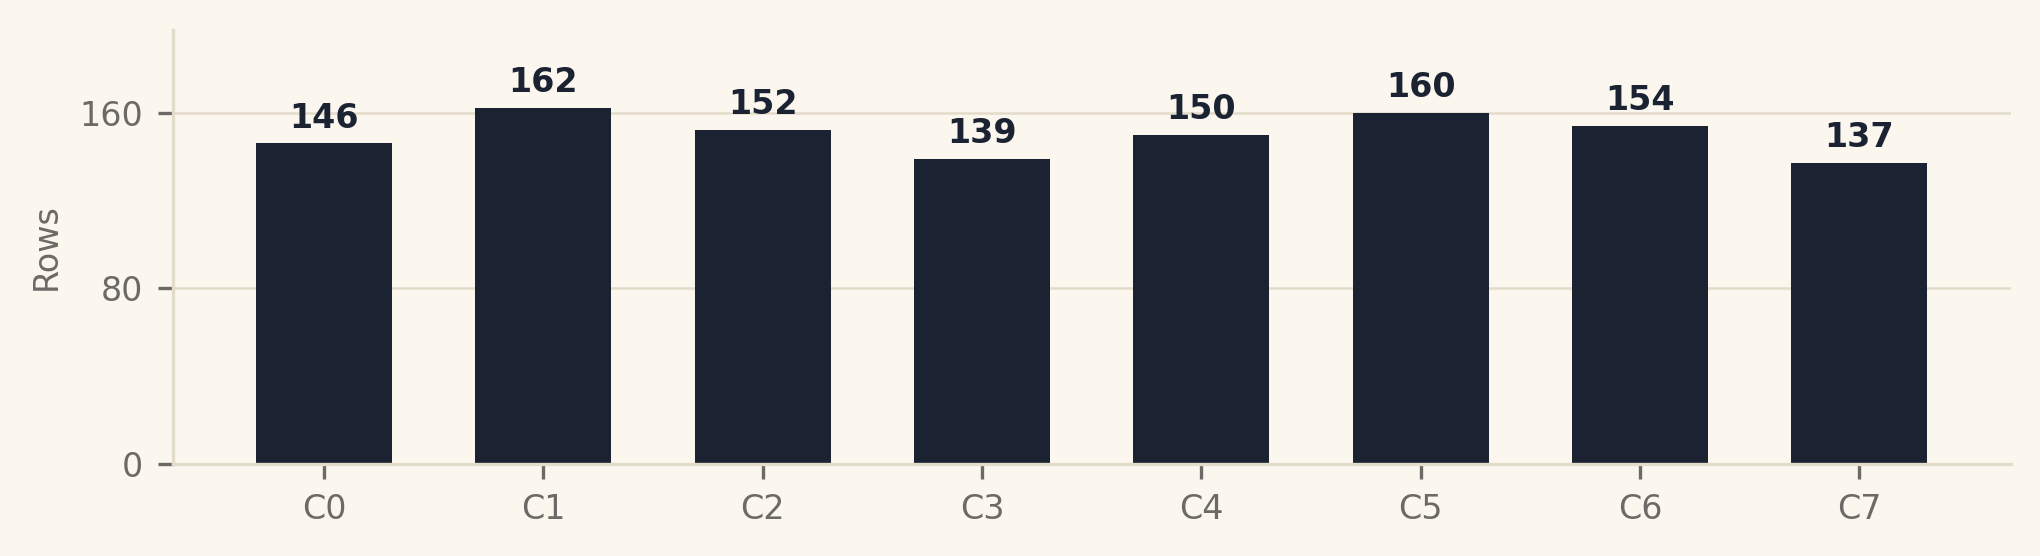

In [42]:
# 03 - Cluster size distribution (slide 7)
sizes = df["Cluster"].value_counts().sort_index()
fig, ax = new_fig(667, 172)
bars = ax.bar([f"C{c}" for c in sizes.index], sizes.values, color=INK, width=0.62)
for b, v in zip(bars, sizes.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, str(v), ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_ylim(0, sizes.max() * 1.22); ax.set_ylabel("Rows"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_locator(plt.MaxNLocator(3))
fig.tight_layout(pad=0.3); save(fig, "03_cluster_size_distribution.png")

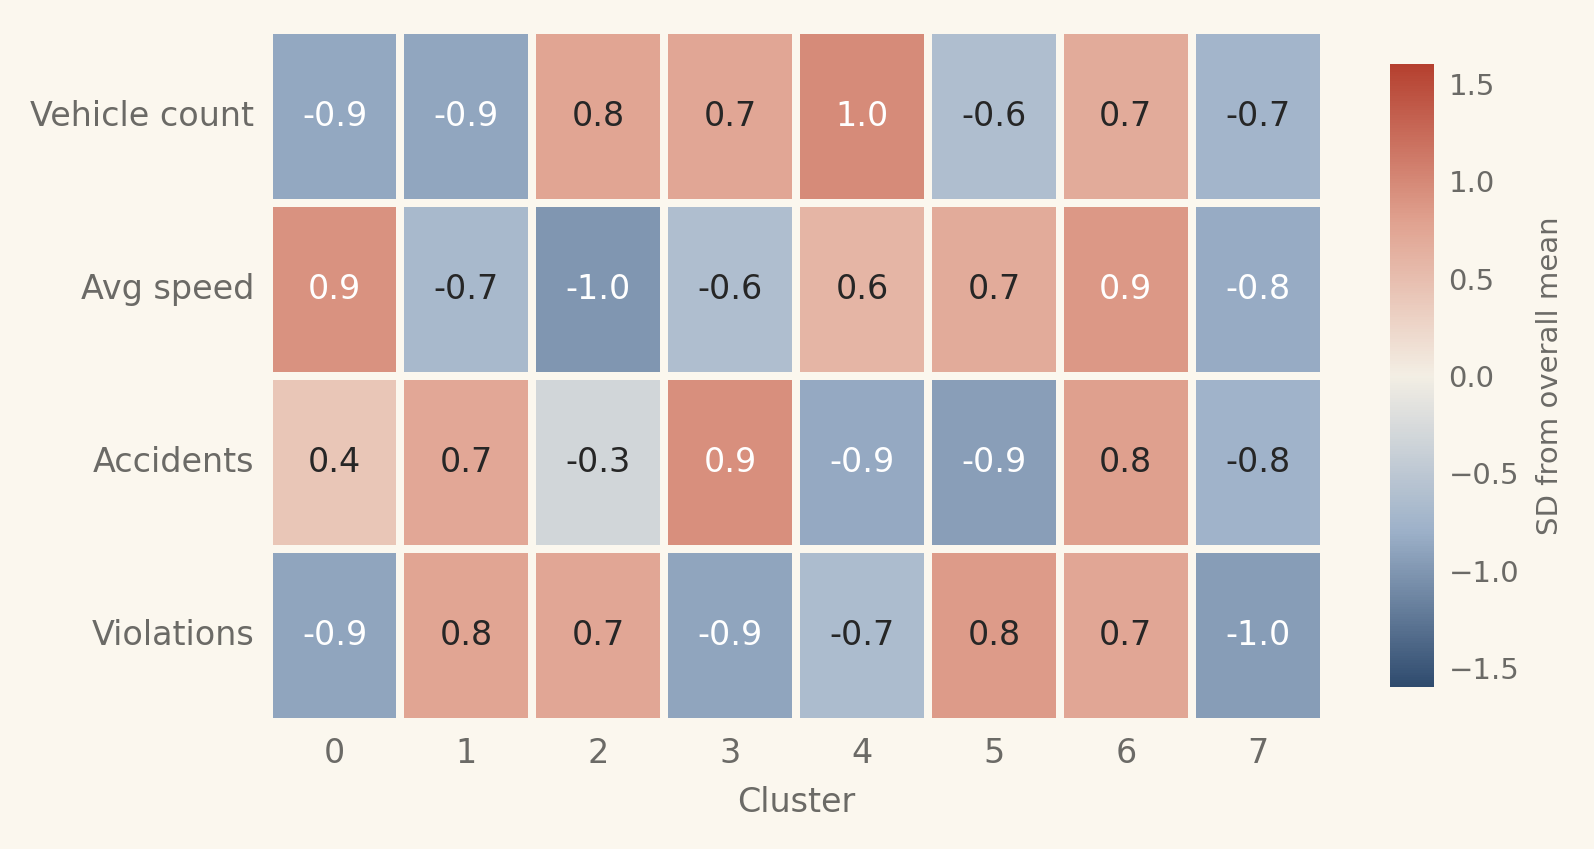

In [43]:
# 04 - Cluster characteristics: standardised cluster means (slide 9)
profile = X_scaled.groupby(df["Cluster"]).mean().T
profile.index = ["Vehicle count", "Avg speed", "Accidents", "Violations"]
fig, ax = new_fig(528, 272)
sns.heatmap(profile, cmap=DIV, center=0, vmin=-1.6, vmax=1.6, annot=True, fmt=".1f", linewidths=1.5, linecolor=SURF,
            annot_kws={"fontsize": 8}, cbar_kws={"shrink": 0.9, "aspect": 14, "label": "SD from overall mean"}, ax=ax)
ax.set_xlabel("Cluster"); ax.set_ylabel(""); ax.grid(False); ax.tick_params(length=0, labelsize=8)
plt.setp(ax.get_yticklabels(), rotation=0)
fig.axes[-1].tick_params(labelsize=7, length=0); fig.axes[-1].yaxis.label.set_size(7)
fig.tight_layout(pad=0.4); save(fig, "04_cluster_characteristics_heatmap.png")

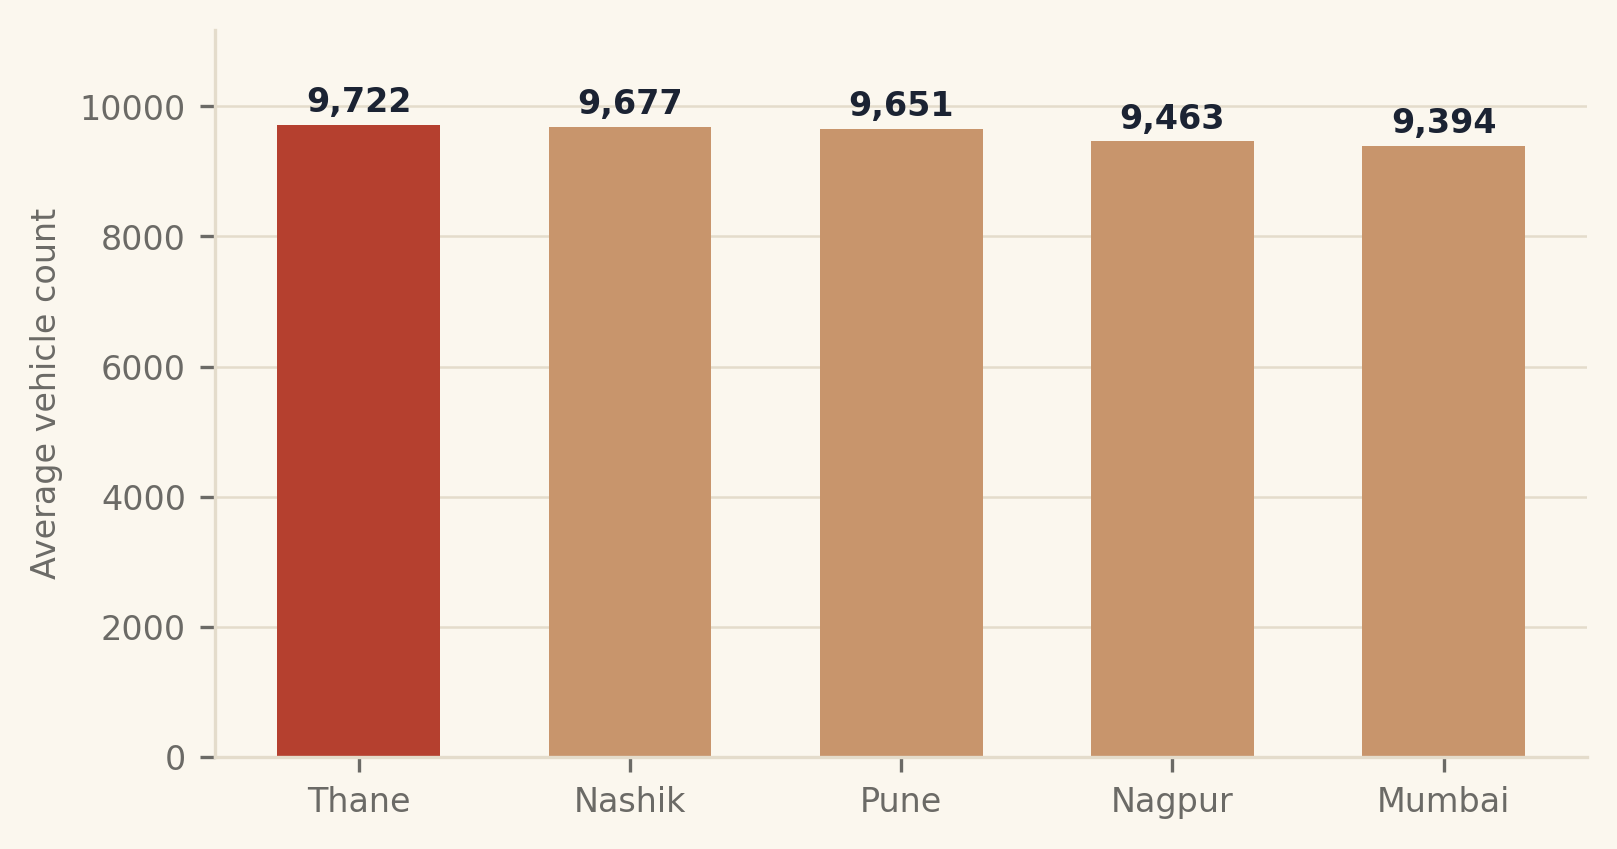

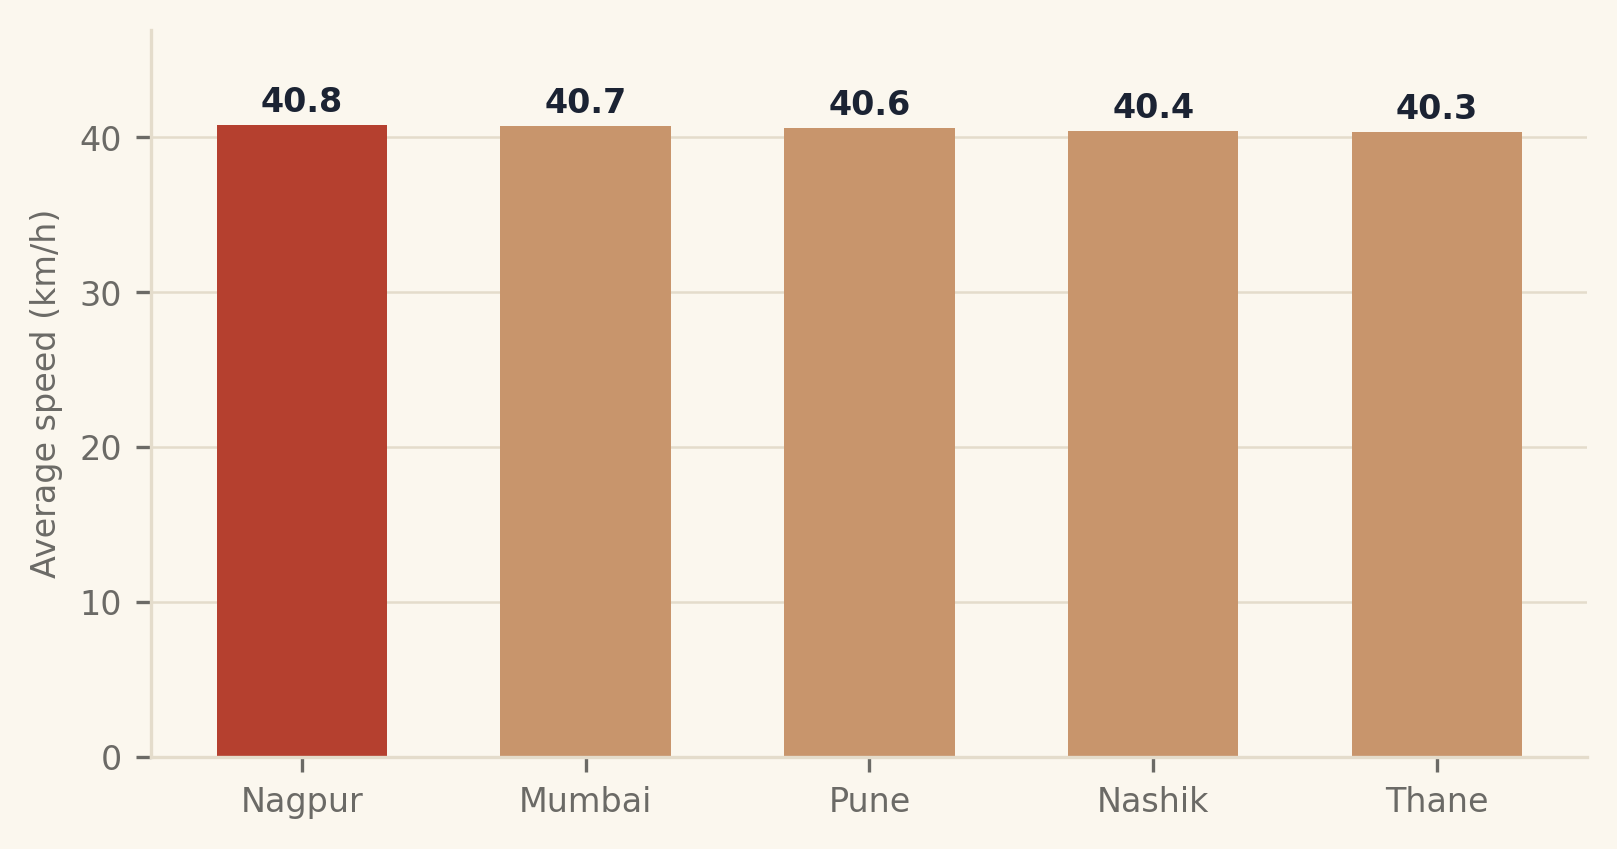

In [44]:
# 05 / 06 - City averages (slide 9)
def city_bar(col, fname, ylabel, fmt, lo_pad):
    s = df.groupby("City")[col].mean().sort_values(ascending=False)
    fig, ax = new_fig(528, 272)
    bars = ax.bar(s.index, s.values, color=[RED] + [TAN] * (len(s) - 1), width=0.6)   # highest city highlighted
    for b, v in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.01, fmt.format(v), ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.set_ylim(0, s.max() * 1.15); ax.set_ylabel(ylabel); ax.grid(axis="x", visible=False)
    fig.tight_layout(pad=0.4); save(fig, fname)
    return s
s_veh = city_bar("Vehicle_Count", "05_city_average_vehicle_count.png", "Average vehicle count", "{:,.0f}", 0)
s_spd = city_bar("Avg_Speed_kmph", "06_city_average_speed.png", "Average speed (km/h)", "{:.1f}", 0)

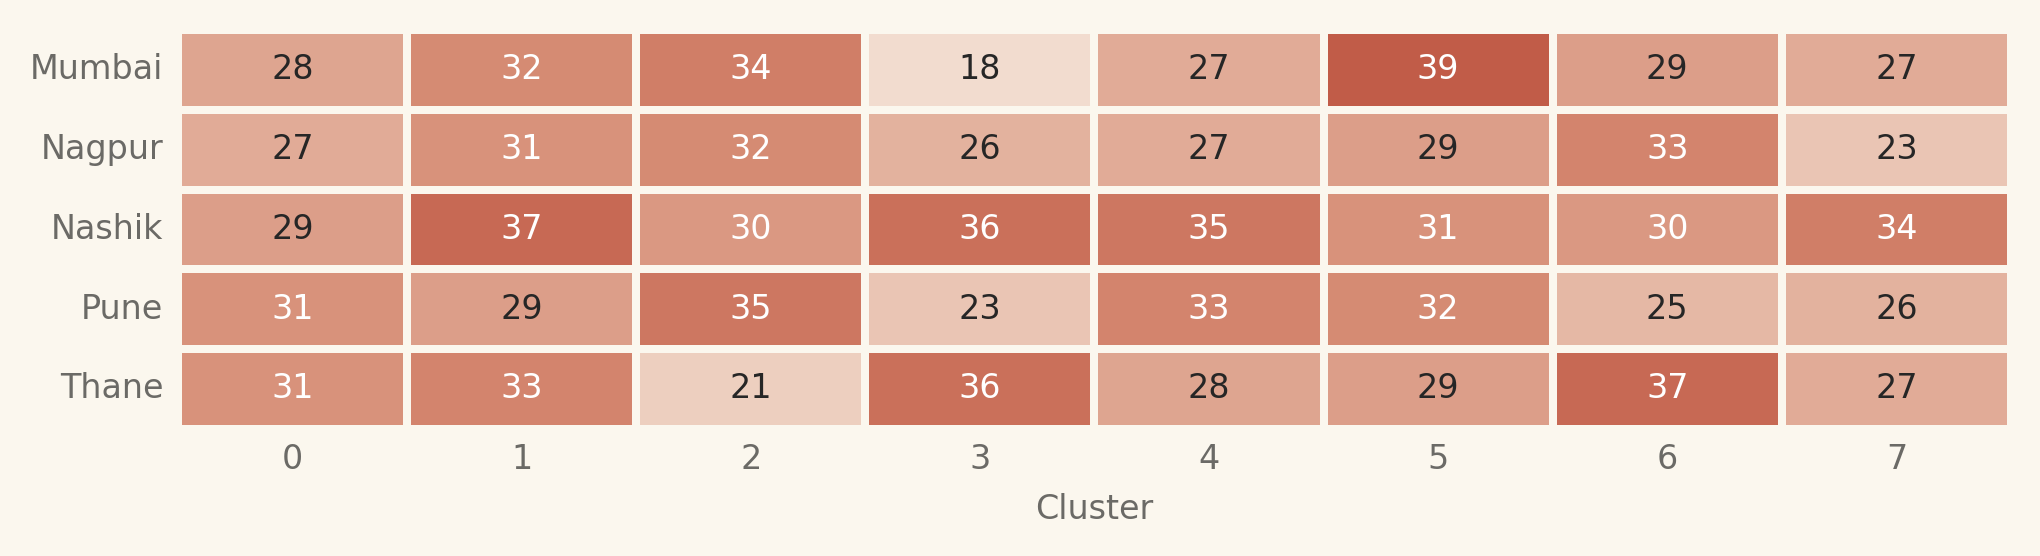

In [45]:
# 07 - City x cluster distribution (slide 7)
cc = pd.crosstab(df["City"], df["Cluster"])
fig, ax = new_fig(667, 172)
sns.heatmap(cc, cmap=SEQ, annot=True, fmt="d", linewidths=1.5, linecolor=SURF, cbar=False, annot_kws={"fontsize": 8}, ax=ax,
            vmin=cc.values.min() - 6, vmax=cc.values.max() + 4)
ax.set_xlabel("Cluster"); ax.set_ylabel(""); ax.grid(False); ax.tick_params(length=0, labelsize=8)
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout(pad=0.3); save(fig, "07_city_cluster_distribution_heatmap.png")

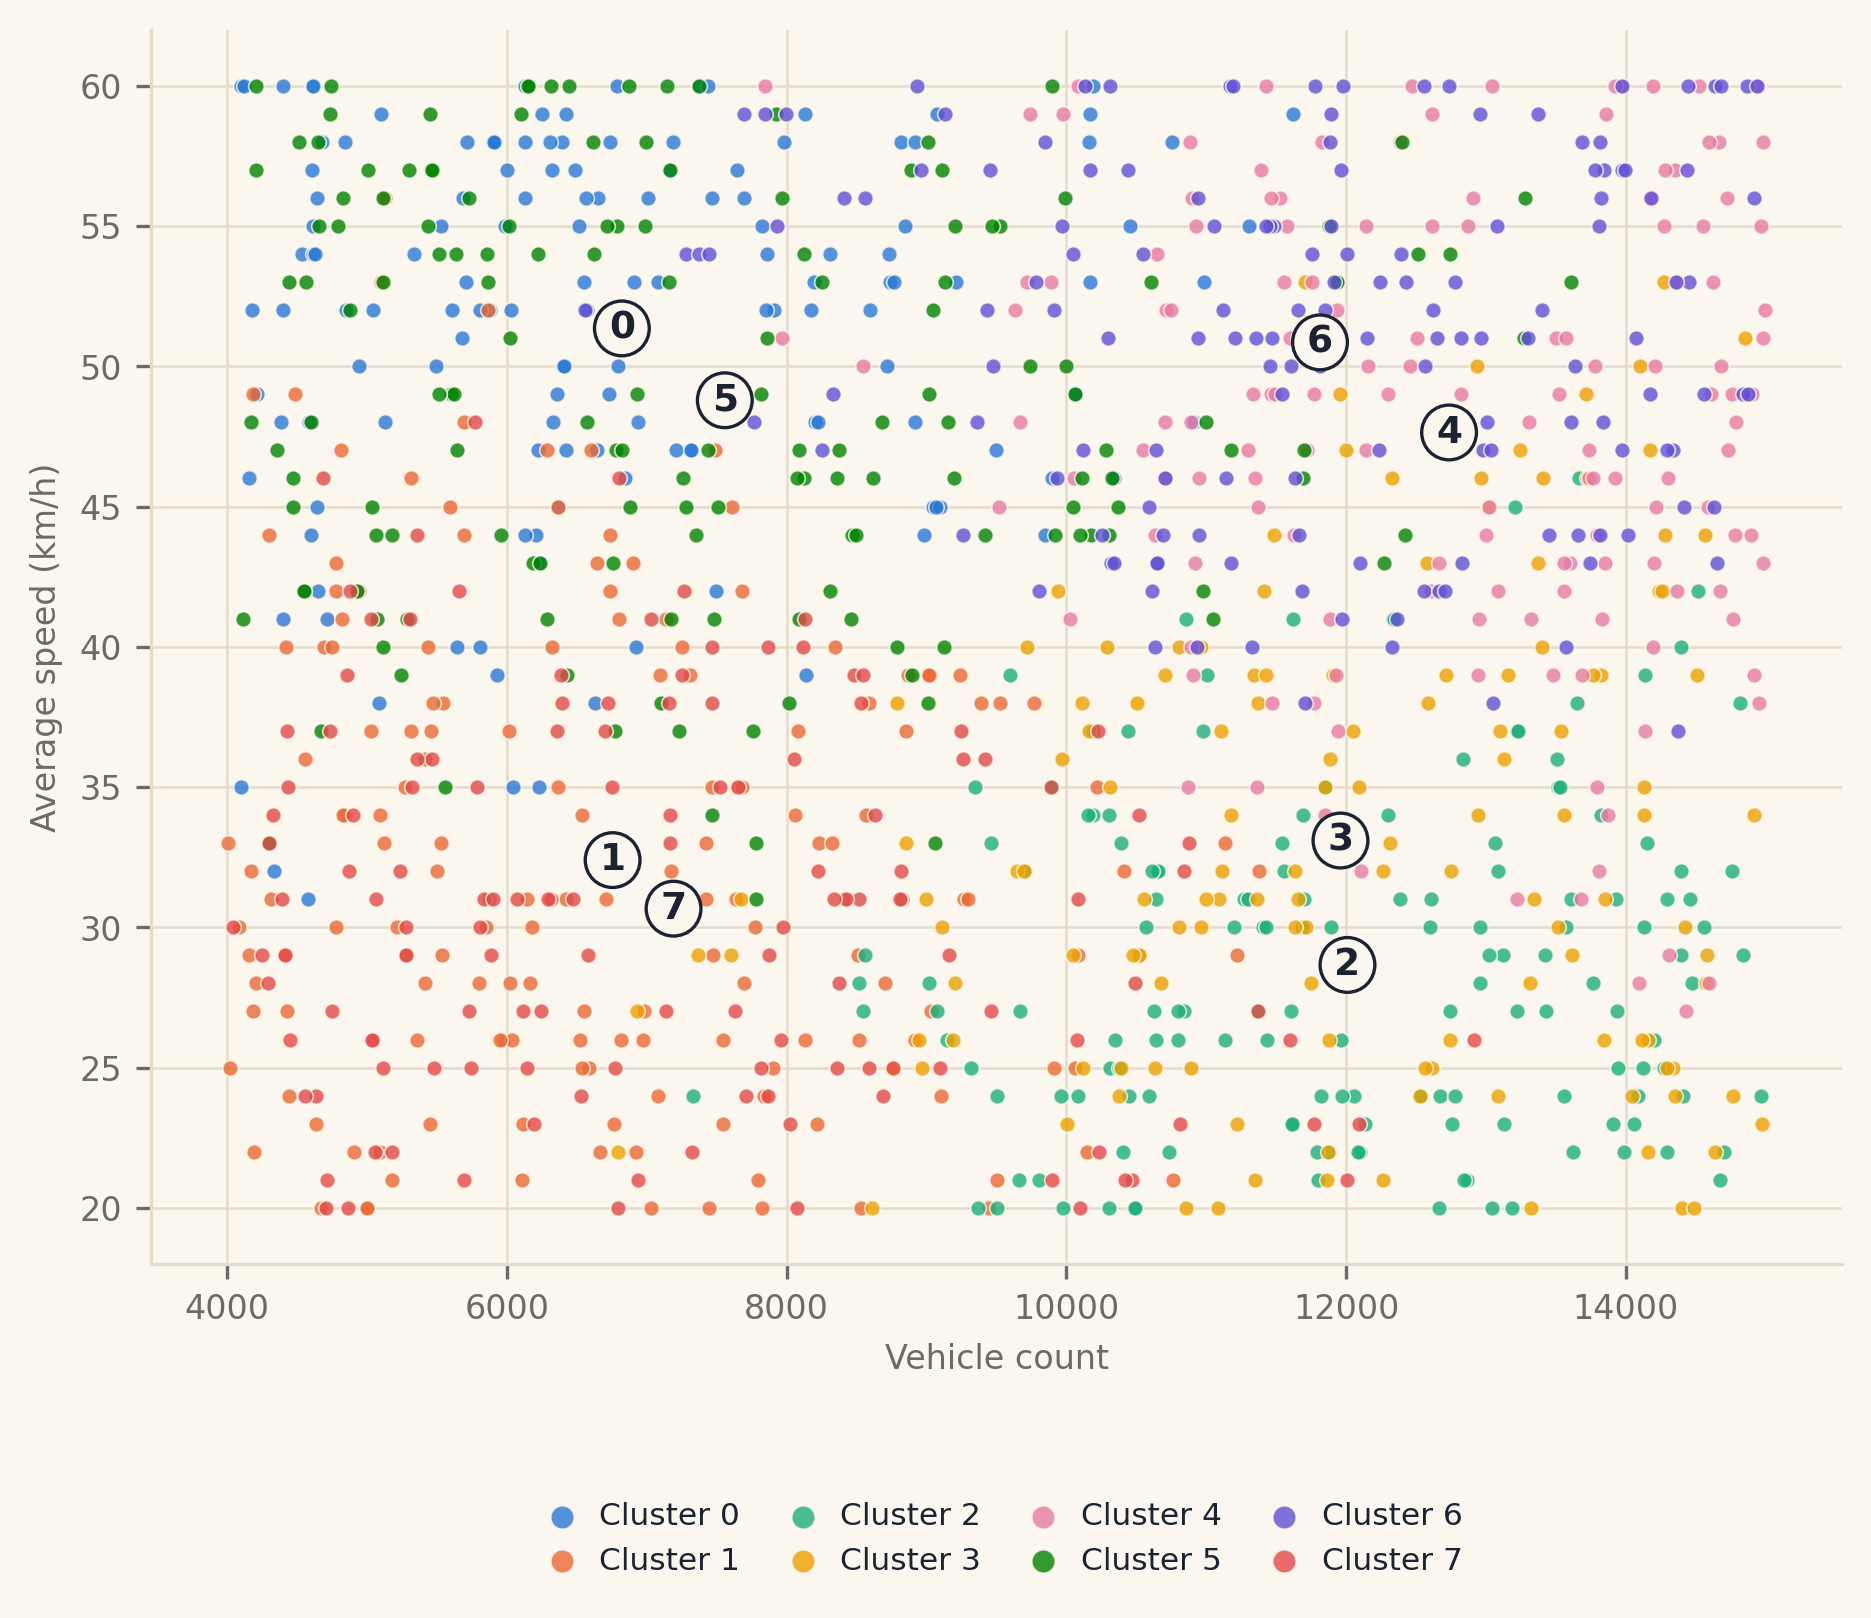

In [46]:
# Extra - cluster scatter (Vehicle count vs speed), not placed on a slide
fig, ax = new_fig(615, 530)
for c in range(8):
    d = df[df["Cluster"] == c]
    ax.scatter(d["Vehicle_Count"], d["Avg_Speed_kmph"], s=14, color=CLUSTER_COLORS[c], alpha=0.8, linewidths=0.4,
               edgecolors=SURF, label=f"Cluster {c}")
for c in range(8):
    d = df[df["Cluster"] == c]
    ax.text(d["Vehicle_Count"].mean(), d["Avg_Speed_kmph"].mean(), str(c), ha="center", va="center", fontsize=9,
            fontweight="bold", color=INK, bbox=dict(boxstyle="circle,pad=0.25", fc=SURF, ec=INK, lw=0.8))
ax.set_xlabel("Vehicle count"); ax.set_ylabel("Average speed (km/h)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, fontsize=7.5, handletextpad=0.2, columnspacing=1.0, markerscale=1.5)
fig.tight_layout(pad=0.5); save(fig, "00_cluster_scatter.png")

## Do the clusters mean anything? Comparison with congestion level

`Congestion_Level` was not used for clustering, so it can serve as an independent check on the clusters.

Congestion_Level,Low,Medium,High
Cluster,,,
0,91,53,2
1,95,64,3
2,0,50,102
3,2,41,96
4,0,29,121
5,75,70,15
6,1,49,104
7,69,62,6


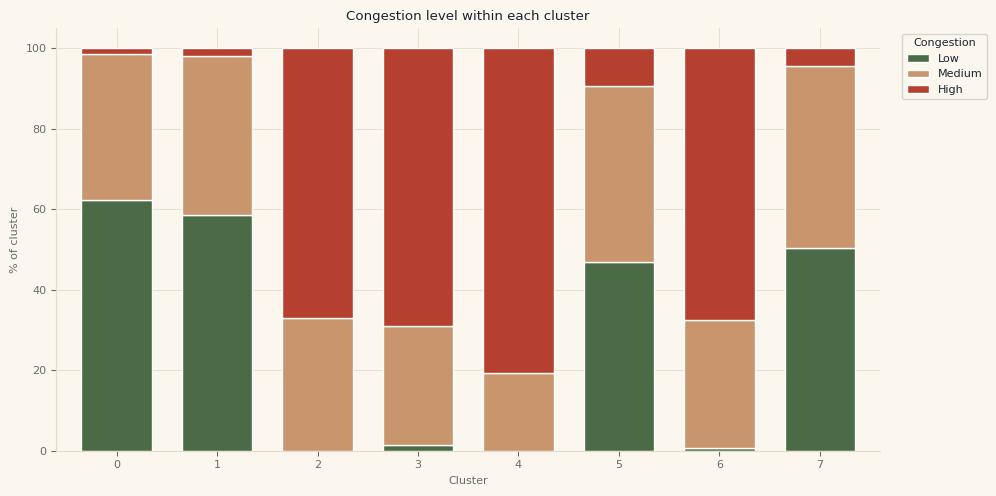

Chi-square test of cluster vs congestion: p = 2.23e-142
Adjusted Rand Index vs congestion level: 0.126

% High congestion per cluster:
 Cluster
0     1.0
1     2.0
2    67.0
3    69.0
4    81.0
5     9.0
6    68.0
7     4.0


In [47]:
from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score
ct = pd.crosstab(df["Cluster"], df["Congestion_Level"])[["Low", "Medium", "High"]]
share = ct.div(ct.sum(axis=1), axis=0) * 100
display(ct)

fig, ax = plt.subplots(figsize=(10, 5))
share.plot(kind="bar", stacked=True, color=[GREEN, TAN, RED], width=0.7, ax=ax, edgecolor="white")
ax.set_ylabel("% of cluster"); ax.set_xlabel("Cluster"); ax.set_title("Congestion level within each cluster")
ax.legend(title="Congestion", bbox_to_anchor=(1.02, 1), loc="upper left"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

chi2, pval, _, _ = chi2_contingency(ct)
print(f"Chi-square test of cluster vs congestion: p = {pval:.2e}")
print(f"Adjusted Rand Index vs congestion level: {adjusted_rand_score(df['Congestion_Level'], df['Cluster']):.3f}")
high = df.groupby("Cluster")["Congestion_Level"].apply(lambda s: (s == "High").mean() * 100).round(0)
print("\n% High congestion per cluster:\n", high.to_string())

**Reading the result.** The clusters are strongly related to congestion (very small p-value). The four high-volume clusters (2, 3, 4, 6) are about 67 to 81% High congestion, while the low-volume clusters (0, 1, 5, 7) are almost never High. So K-Means is mainly recovering the **vehicle-count tiers**. The low Adjusted Rand Index (about 0.13) shows the clusters are not a copy of congestion: speed, accidents and violations split each tier further, but those features carry little structure, which is why the silhouette score is only 0.2376.

## Recheck: every number quoted in the deck

In [48]:
checks = {
    "1,200 observations":            len(df) == 1200,
    "no missing values":              int(df.isnull().sum().sum()) == 0,
    "no duplicate rows":              int(df.duplicated().sum()) == 0,
    "5 cities":                       df["City"].nunique() == 5,
    "8 clusters":                     df["Cluster"].nunique() == 8,
    "silhouette = 0.2376":            round(silhouette_score(X_scaled, df["Cluster"]), 4) == 0.2376,
    "cluster sizes 146,162,152,139,150,160,154,137": df["Cluster"].value_counts().sort_index().tolist() == [146, 162, 152, 139, 150, 160, 154, 137],
    "cluster sizes sum to 1,200":     int(df["Cluster"].value_counts().sum()) == 1200,
    "city x cluster table sums to 1,200": int(cc.values.sum()) == 1200,
    "silhouette is highest at K = 8": ks[int(np.argmax(silhouette_scores))] == 8,
    "all 8 figures saved":            len([f for f in os.listdir(OUT) if f.endswith(".png")]) == 8,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values()), "A deck number no longer matches the data"

PASS - 1,200 observations
PASS - no missing values
PASS - no duplicate rows
PASS - 5 cities
PASS - 8 clusters
PASS - silhouette = 0.2376
PASS - cluster sizes 146,162,152,139,150,160,154,137
PASS - cluster sizes sum to 1,200
PASS - city x cluster table sums to 1,200
PASS - silhouette is highest at K = 8
PASS - all 8 figures saved


---
# CCE V: Extension of the Traffic Pattern Project

**What CCE IV did:** K-Means clustering (K = 8) on four numeric features; silhouette score 0.2376.

**Problem statement (CCE V):** Can we (a) find the most reliable way to group traffic observations, and (b) predict the congestion level of a location-day? We also want to know *how much the answer depends on `Vehicle_Count`*, because the EDA showed that congestion is defined by vehicle count alone.

**Objectives**
1. **Part A, Unsupervised:** compare K-Means, Gaussian Mixture, Agglomerative and DBSCAN on a baseline and an extended feature set (city, vehicle type, month, day of week), using three internal metrics. Check how stable the clusters are and visualise them with PCA.
2. **Part B, Supervised:** classify `Congestion_Level` with Logistic Regression, Decision Tree, Random Forest and Gradient Boosting. Do it twice, with and without `Vehicle_Count`, to expose **target leakage** and report honest accuracy.
3. Turn the results into practical conclusions.

In [49]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["Month_sin"], df["Month_cos"] = np.sin(2*np.pi*df["Month"]/12), np.cos(2*np.pi*df["Month"]/12)
df["Dow_sin"], df["Dow_cos"] = np.sin(2*np.pi*df["DayOfWeek"]/7), np.cos(2*np.pi*df["DayOfWeek"]/7)
print("Added calendar features. Shape:", df.shape)

Added calendar features. Shape: (1200, 17)


## Part A: Clustering, a model comparison

### A1. Two feature sets
* **Baseline:** the four numeric features used in CCE IV.
* **Extended:** baseline + one-hot City and Vehicle_Type + cyclical month and day-of-week (sin/cos, so December sits next to January).

This tests the "future work" from CCE IV: do city, vehicle type and date add structure?

In [50]:
num_cols = ["Vehicle_Count", "Avg_Speed_kmph", "Accidents", "Traffic_Violations"]

X_base = StandardScaler().fit_transform(df[num_cols])

cat_ohe = pd.get_dummies(df[["City", "Vehicle_Type"]], dtype=float)
cal = df[["Month_sin", "Month_cos", "Dow_sin", "Dow_cos"]]
X_ext = StandardScaler().fit_transform(pd.concat([df[num_cols], cat_ohe, cal], axis=1))

print("Baseline feature matrix:", X_base.shape)
print("Extended feature matrix:", X_ext.shape)

Baseline feature matrix: (1200, 4)
Extended feature matrix: (1200, 18)


### A2. Comparing four algorithms (K = 8, matching CCE IV)
Three internal metrics:
* **Silhouette** (higher is better, max 1)
* **Davies-Bouldin** (lower is better)
* **Calinski-Harabasz** (higher is better)

DBSCAN has no K. We pick `eps` from the k-distance curve (the "knee") and let it find its own clusters; points it cannot place are labelled noise (-1) and left out of the metrics.

In [51]:
def dbscan_labels(X, min_samples=10):
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
    kd = np.sort(d[:, -1])
    eps = np.percentile(kd, 90)          # knee approximated by the 90th percentile of k-distances
    return DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X), eps

def evaluate(X, labels):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    if n_clusters < 2:
        return dict(clusters=n_clusters, noise=int((~mask).sum()), silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(clusters=n_clusters, noise=int((~mask).sum()),
                silhouette=silhouette_score(X[mask], labels[mask]),
                davies_bouldin=davies_bouldin_score(X[mask], labels[mask]),
                calinski_harabasz=calinski_harabasz_score(X[mask], labels[mask]))

K = 8
rows, store = [], {}
for fs_name, X in [("Baseline (4 numeric)", X_base), ("Extended (+city, vehicle, date)", X_ext)]:
    models = {
        "K-Means":       KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(X),
        "Gaussian Mixture": GaussianMixture(K, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(X).predict(X),
        "Agglomerative (Ward)": AgglomerativeClustering(K, linkage="ward").fit_predict(X),
    }
    db_lab, eps = dbscan_labels(X)
    models[f"DBSCAN (eps={eps:.2f})"] = db_lab
    for name, lab in models.items():
        rows.append({"Feature set": fs_name, "Algorithm": name, **evaluate(X, lab)})
        store[(fs_name, name)] = lab

comparison = pd.DataFrame(rows).round(4)
display(comparison)

,Feature set,Algorithm,clusters,noise,silhouette,davies_bouldin,calinski_harabasz
0,Baseline (4 numeric),K-Means,8,0,0.2376,1.1217,281.1822
1,Baseline (4 numeric),Gaussian Mixture,8,0,0.1627,1.3554,210.1963
2,Baseline (4 numeric),Agglomerative (Ward),8,0,0.1471,1.4150,203.5172
3,Baseline (4 numeric),DBSCAN (eps=0.87),1,0,NaN,NaN,NaN
4,"Extended (+city, vehicle, date)",K-Means,8,0,0.1161,1.9230,83.6297
5,"Extended (+city, vehicle, date)",Gaussian Mixture,8,0,0.1186,1.9916,82.1295
6,"Extended (+city, vehicle, date)",Agglomerative (Ward),8,0,0.1201,1.9749,83.1507
7,"Extended (+city, vehicle, date)",DBSCAN (eps=3.59),14,1,0.0888,2.1718,44.8043


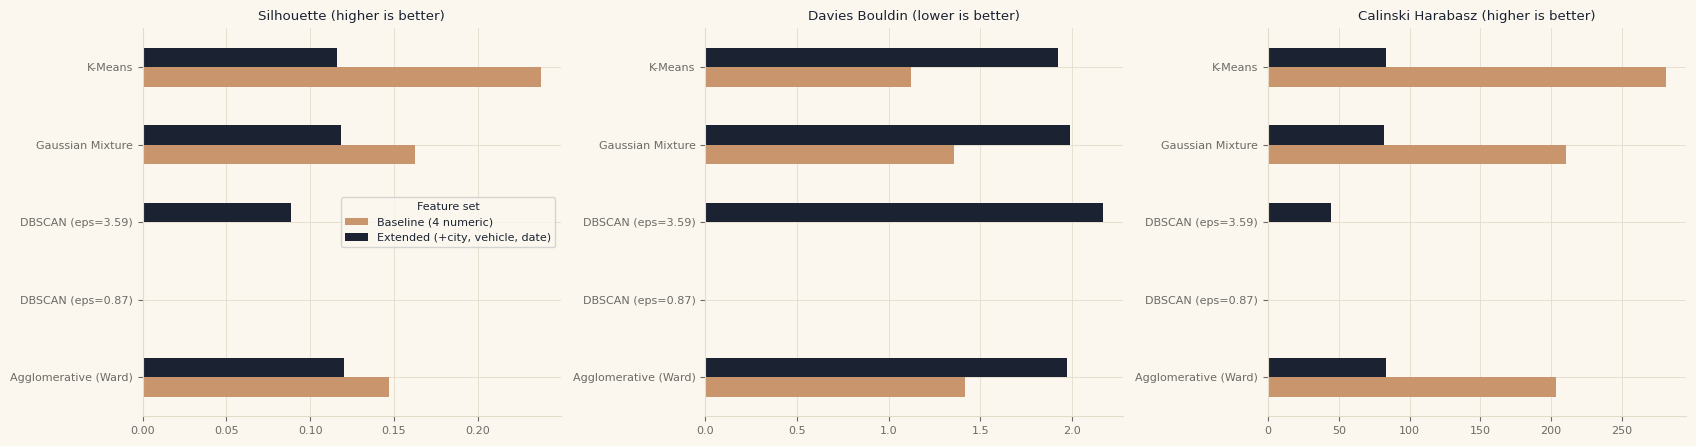

In [52]:
# Visual comparison of the three metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric, better in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                              ["higher is better", "lower is better", "higher is better"]):
    pv = comparison.pivot(index="Algorithm", columns="Feature set", values=metric)
    pv.plot(kind="barh", ax=ax, color=["#C8956C", "#1B2333"], legend=(metric == "silhouette"))
    ax.set_title(f"{metric.replace('_', ' ').title()} ({better})"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### A3. How many clusters? Stability analysis
A good K should give the *same* clusters when the data is slightly changed. For each K we draw 30 bootstrap samples, fit K-Means on each, label the full dataset, and compare with a reference clustering using the **Adjusted Rand Index** (1 = identical, 0 = random).

,K,Silhouette,Stability (mean ARI),Stability (std)
0,2,0.191,0.303,0.417
1,3,0.184,0.363,0.307
2,4,0.200,0.406,0.218
3,5,0.201,0.430,0.151
4,6,0.204,0.413,0.095
5,7,0.220,0.522,0.147
6,8,0.238,0.645,0.194
7,9,0.230,0.572,0.120
8,10,0.225,0.525,0.089


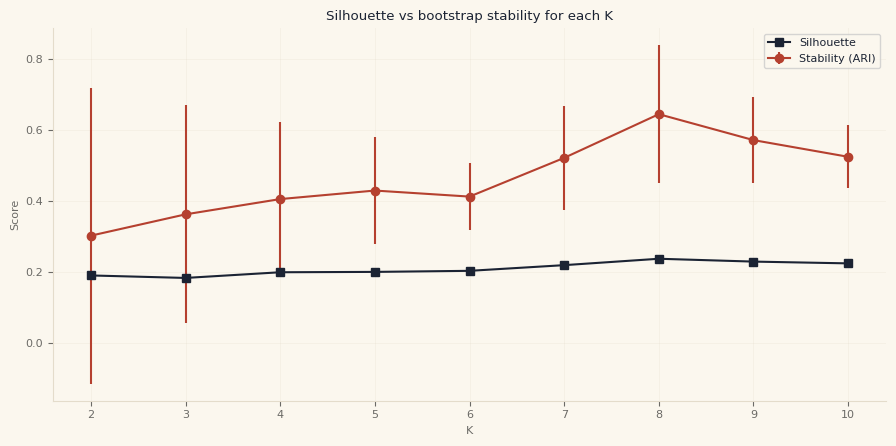

In [53]:
rng = np.random.RandomState(RANDOM_STATE)
def stability(X, k, n_boot=30):
    ref = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X).labels_
    scores = []
    for b in range(n_boot):
        idx = rng.choice(len(X), len(X), replace=True)
        lab = KMeans(k, n_init=5, random_state=b).fit(X[idx]).predict(X)
        scores.append(adjusted_rand_score(ref, lab))
    return np.mean(scores), np.std(scores)

res = []
for k in range(2, 11):
    m, s = stability(X_base, k)
    sil = silhouette_score(X_base, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_base))
    res.append({"K": k, "Silhouette": sil, "Stability (mean ARI)": m, "Stability (std)": s})
stab = pd.DataFrame(res).round(3)
display(stab)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(stab["K"], stab["Stability (mean ARI)"], yerr=stab["Stability (std)"], marker="o", color="#B5402F", label="Stability (ARI)")
ax.plot(stab["K"], stab["Silhouette"], marker="s", color="#1B2333", label="Silhouette")
ax.set_xlabel("K"); ax.set_ylabel("Score"); ax.set_title("Silhouette vs bootstrap stability for each K")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### A4. Visualising the clusters with PCA
If the clusters were well separated, a 2-D projection would show clear blobs. We also print how much variance the first components keep.

Explained variance ratio per component: [0.265 0.254 0.246 0.235]
Cumulative (2 components): 0.519


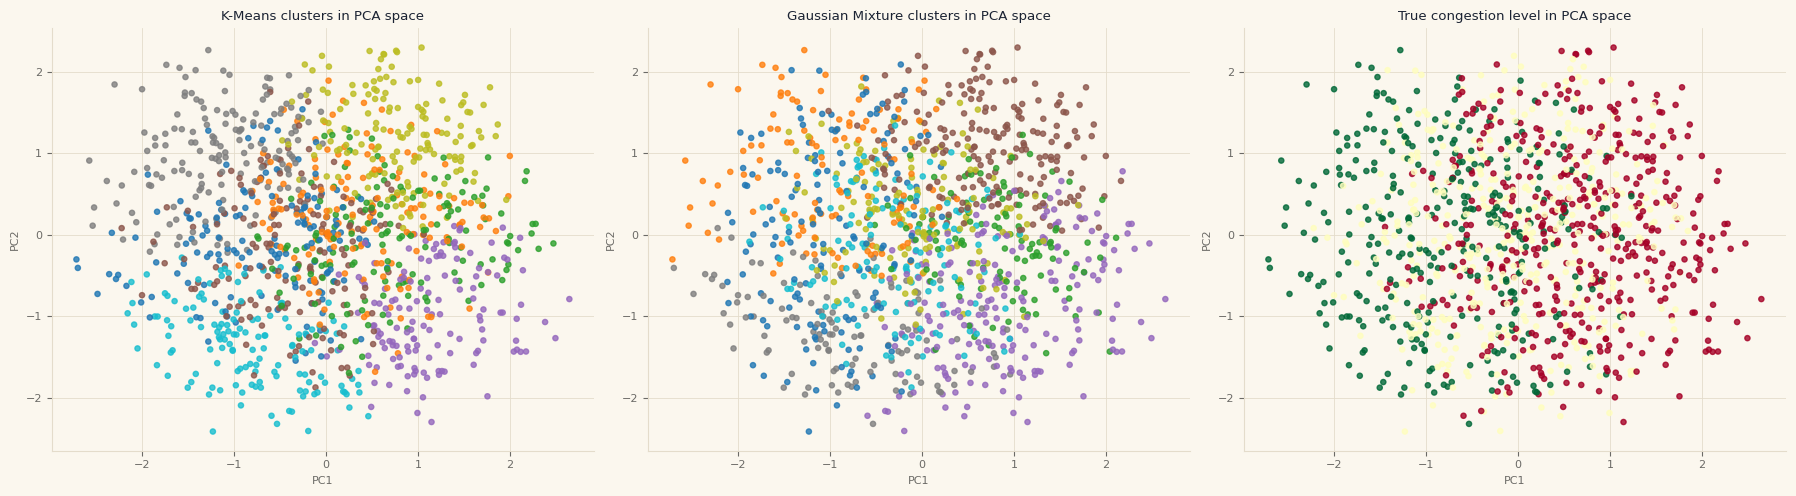


PCA loadings:


,PC1,PC2
Vehicle_Count,0.58,0.01
Avg_Speed_kmph,-0.38,0.61
Accidents,0.70,0.10
Traffic_Violations,0.20,0.79


In [54]:
pca = PCA(n_components=4, random_state=RANDOM_STATE).fit(X_base)
print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(3))
print("Cumulative (2 components):", pca.explained_variance_ratio_[:2].sum().round(3))

Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_base)
km_labels = store[("Baseline (4 numeric)", "K-Means")]
gm_labels = store[("Baseline (4 numeric)", "Gaussian Mixture")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab, title in [(axes[0], km_labels, "K-Means clusters"),
                       (axes[1], gm_labels, "Gaussian Mixture clusters"),
                       (axes[2], df["Congestion_Level"].map({"Low": 0, "Medium": 1, "High": 2}).values, "True congestion level")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10" if "level" not in title else "RdYlGn_r", s=14, alpha=.8)
    ax.set_title(title + " in PCA space"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=num_cols, columns=["PC1", "PC2"]).round(2)
print("\nPCA loadings:"); display(loadings)

### A5. Naming the clusters (K-Means, K = 8)
Each cluster is described in plain language so it can be used by a traffic planner.

In [55]:
df["Cluster"] = km_labels
prof = df.groupby("Cluster").agg(Size=("Cluster", "size"),
                                 Vehicle_Count=("Vehicle_Count", "mean"),
                                 Speed=("Avg_Speed_kmph", "mean"),
                                 Accidents=("Accidents", "mean"),
                                 Violations=("Traffic_Violations", "mean"),
                                 High_congestion_pct=("Congestion_Level", lambda s: 100 * (s == "High").mean())).round(1)

def level(v, lo, hi): return "low" if v <= lo else ("high" if v >= hi else "mid")
q = prof.quantile([.33, .67])
prof["Profile"] = [f"{level(r.Vehicle_Count, q.loc[.33,'Vehicle_Count'], q.loc[.67,'Vehicle_Count'])} volume, "
                   f"{level(r.Speed, q.loc[.33,'Speed'], q.loc[.67,'Speed'])} speed, "
                   f"{level(r.Accidents, q.loc[.33,'Accidents'], q.loc[.67,'Accidents'])} accidents"
                   for r in prof.itertuples()]
display(prof.sort_values("Vehicle_Count", ascending=False))

,Size,Vehicle_Count,Speed,Accidents,Violations,High_congestion_pct,Profile
Cluster,,,,,,,
4,150,12735.5,47.6,1.8,121.4,80.7,"high volume, mid speed, low accidents"
2,152,12009.2,28.7,3.2,228.7,67.1,"high volume, low speed, mid accidents"
3,139,11959.2,33.1,6.4,103.5,69.1,"high volume, mid speed, high accidents"
6,154,11812.9,50.9,6.1,228.4,67.5,"mid volume, high speed, high accidents"
5,160,7557.7,48.8,1.6,236.1,9.4,"mid volume, high speed, low accidents"
7,137,7191.3,30.7,2.1,98.6,4.4,"low volume, low speed, low accidents"
0,146,6821.8,51.3,5.1,103.6,1.4,"low volume, high speed, mid accidents"
1,162,6755.6,32.4,5.9,229.4,1.9,"low volume, low speed, high accidents"


### Part A summary
* **Best method: plain K-Means on the four baseline features.** It leads on all three metrics (silhouette 0.238, Davies-Bouldin 1.12, Calinski-Harabasz 281). Gaussian Mixture (0.163) and Agglomerative (0.147) are clearly lower.
* **DBSCAN finds only one cluster on the baseline features.** The points form one dense, evenly spread cloud with no low-density gaps, which is why density-based methods cannot split it. On the extended features it returns many small clusters with the lowest scores.
* **Adding city, vehicle type and date features made every algorithm worse** (silhouette about 0.12 or lower). One-hot columns add dimensions with no real structure, so this confirms that these variables carry no extra pattern.
* **K = 8 is supported by two independent checks.** It has the highest silhouette (0.238) and the highest bootstrap stability (mean ARI about 0.65) among K = 2 to 10, which justifies the CCE IV choice.
* **PCA shows the four features are nearly independent.** The four components each explain about 25% of the variance and two keep only about 52%, so no 2-D picture can show clean blobs. This matches the near-zero correlations in the EDA.
* **Practical reading of the clusters.** The four highest-volume clusters have 67-81% High congestion, and the four lower-volume clusters have 9% or less. They then differ in speed, accidents and violations, which can guide where to focus enforcement or road-safety work.

## Part B: Classification, predicting `Congestion_Level`

### B1. First, a warning from the data
The EDA found that congestion is determined by `Vehicle_Count` alone. We confirm the exact rule below. If the label is a deterministic function of one input, any model that sees that input will be "accurate" without learning anything. That is **target leakage**, so we evaluate two feature sets.

In [56]:
rule = df.groupby("Congestion_Level")["Vehicle_Count"].agg(["min", "max", "count"]).loc[["Low", "Medium", "High"]]
display(rule)
overlap = (rule["min"].shift(-1) <= rule["max"]).fillna(False).any()
print("Do the vehicle-count ranges of neighbouring classes overlap?", bool(overlap))
print("\nClass balance:"); print(df["Congestion_Level"].value_counts(normalize=True).round(3))

,min,max,count
Congestion_Level,,,
Low,4008,6991,333
Medium,7011,10999,418
High,11003,14993,449


Do the vehicle-count ranges of neighbouring classes overlap? False

Class balance:
Congestion_Level
High      0.374
Medium    0.348
Low       0.278
Name: proportion, dtype: float64


### B2. Setup
* **Leakage-free features:** City, Area, Vehicle_Type, Avg_Speed_kmph, Accidents, Traffic_Violations, Month, DayOfWeek (no `Vehicle_Count`). This is the honest, deployable setting.
* **Leaky features:** the same plus `Vehicle_Count`, to demonstrate the leakage.
* Stratified 80/20 split, plus 5-fold stratified cross-validation.
* A **majority-class baseline** is included. Any real model must beat it.

In [57]:
target = "Congestion_Level"
cat_feats = ["City", "Area", "Vehicle_Type"]
num_feats_clean = ["Avg_Speed_kmph", "Accidents", "Traffic_Violations", "Month", "DayOfWeek"]
feats_clean = cat_feats + num_feats_clean
feats_leaky = feats_clean + ["Vehicle_Count"]

y = df[target]
class_order = ["Low", "Medium", "High"]

def make_pipe(model, num_feats):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
                             ("num", StandardScaler(), num_feats)])
    return Pipeline([("pre", pre), ("clf", model)])

zoo = {
    "Majority baseline":   DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def run_cv(feats, label):
    out = []
    num_feats = [c for c in feats if c not in cat_feats]
    for name, m in zoo.items():
        r = cross_validate(make_pipe(m, num_feats), df[feats], y, cv=cv,
                           scoring=["accuracy", "f1_macro"], n_jobs=-1)
        out.append({"Feature set": label, "Model": name,
                    "Accuracy": r["test_accuracy"].mean(), "Accuracy std": r["test_accuracy"].std(),
                    "Macro F1": r["test_f1_macro"].mean()})
    return pd.DataFrame(out)

cv_clean = run_cv(feats_clean, "Leakage-free (no Vehicle_Count)")
cv_leaky = run_cv(feats_leaky, "With Vehicle_Count (leaky)")
cv_all = pd.concat([cv_clean, cv_leaky]).round(4)
display(cv_all)

,Feature set,Model,Accuracy,Accuracy std,Macro F1
0,Leakage-free (no Vehicle_Count),Majority baseline,0.3742,0.0017,0.1815
1,Leakage-free (no Vehicle_Count),Logistic Regression,0.3575,0.0377,0.3262
2,Leakage-free (no Vehicle_Count),Decision Tree,0.3817,0.0371,0.3319
3,Leakage-free (no Vehicle_Count),Random Forest,0.3658,0.0150,0.3473
4,Leakage-free (no Vehicle_Count),Gradient Boosting,0.3667,0.0225,0.3509
0,With Vehicle_Count (leaky),Majority baseline,0.3742,0.0017,0.1815
1,With Vehicle_Count (leaky),Logistic Regression,0.9692,0.0202,0.9689
2,With Vehicle_Count (leaky),Decision Tree,0.9992,0.0017,0.9992
3,With Vehicle_Count (leaky),Random Forest,0.9983,0.0020,0.9983
4,With Vehicle_Count (leaky),Gradient Boosting,0.9992,0.0017,0.9992


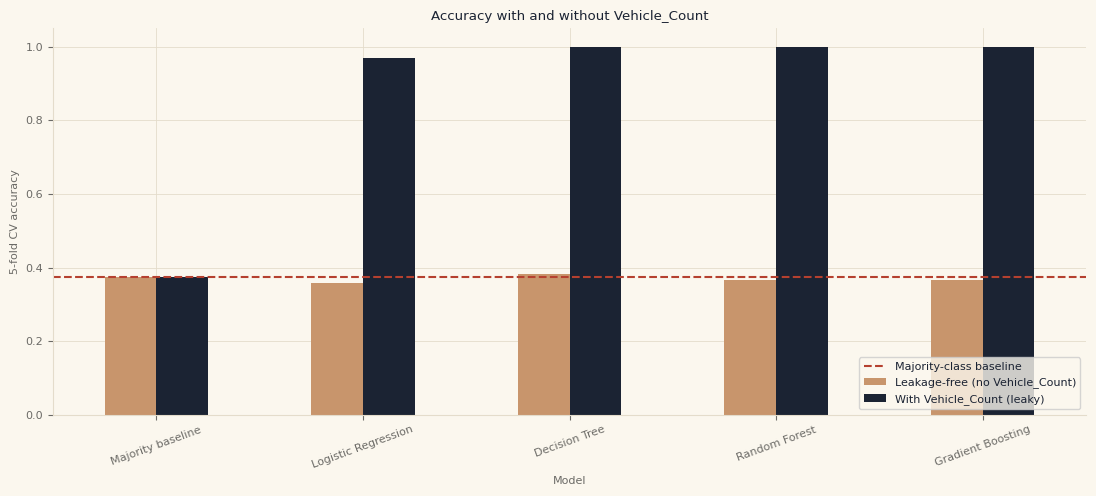

In [58]:
fig, ax = plt.subplots(figsize=(11, 5))
pv = cv_all.pivot(index="Model", columns="Feature set", values="Accuracy").loc[list(zoo)]
pv.plot(kind="bar", ax=ax, color=["#C8956C", "#1B2333"])
ax.axhline(y.value_counts(normalize=True).max(), color="#B5402F", ls="--", label="Majority-class baseline")
ax.set_ylabel("5-fold CV accuracy"); ax.set_ylim(0, 1.05); ax.set_title("Accuracy with and without Vehicle_Count")
plt.xticks(rotation=20); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### B3. Detailed evaluation on a held-out test set
Confusion matrices and per-class metrics for the **best model of each setting** on the 20% test split.

Best leakage-free model: Decision Tree | Best leaky model: Decision Tree

=== Leakage-free: Decision Tree ===
              precision    recall  f1-score   support

         Low      0.250     0.121     0.163        66
      Medium      0.315     0.405     0.354        84
        High      0.350     0.389     0.368        90

    accuracy                          0.321       240
   macro avg      0.305     0.305     0.295       240
weighted avg      0.310     0.321     0.307       240


=== With Vehicle_Count: Decision Tree ===
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000        66
      Medium      1.000     1.000     1.000        84
        High      1.000     1.000     1.000        90

    accuracy                          1.000       240
   macro avg      1.000     1.000     1.000       240
weighted avg      1.000     1.000     1.000       240



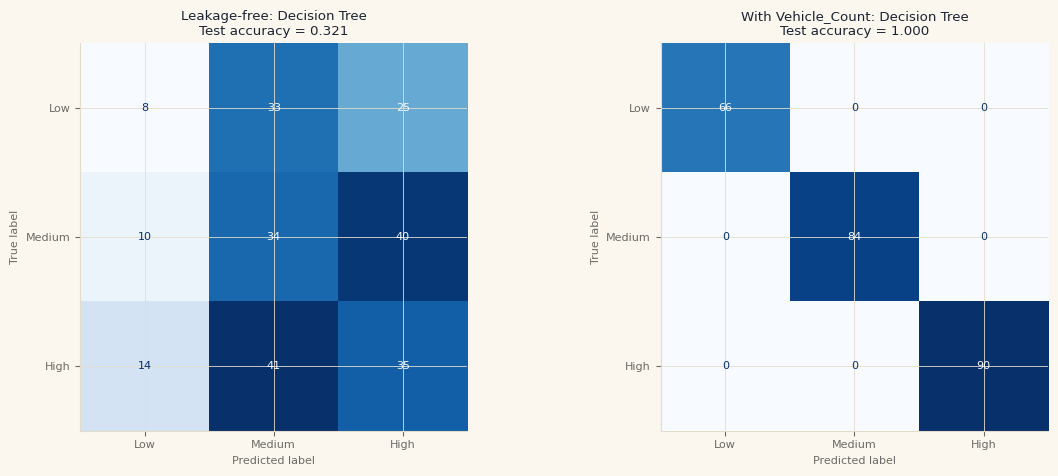

In [59]:
Xtr_c, Xte_c, ytr, yte = train_test_split(df[feats_clean], y, test_size=.2, stratify=y, random_state=RANDOM_STATE)
Xtr_l, Xte_l = df.loc[Xtr_c.index, feats_leaky], df.loc[Xte_c.index, feats_leaky]

best_clean = cv_clean[cv_clean["Model"] != "Majority baseline"].sort_values("Accuracy", ascending=False).iloc[0]["Model"]
best_leaky = cv_leaky.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
print("Best leakage-free model:", best_clean, "| Best leaky model:", best_leaky)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, feats, Xtr, Xte, mname) in zip(axes, [
        ("Leakage-free", feats_clean, Xtr_c, Xte_c, best_clean),
        ("With Vehicle_Count", feats_leaky, Xtr_l, Xte_l, best_leaky)]):
    pipe = make_pipe(zoo[mname], [c for c in feats if c not in cat_feats]).fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=class_order), display_labels=class_order).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}: {mname}\nTest accuracy = {accuracy_score(yte, pred):.3f}")
    print(f"\n=== {title}: {mname} ===")
    print(classification_report(yte, pred, labels=class_order, digits=3))
plt.tight_layout(); plt.show()

### B4. What is the model actually using? (permutation importance)
Permutation importance shuffles one feature at a time and measures the drop in accuracy. A large drop means the model relies on that feature.

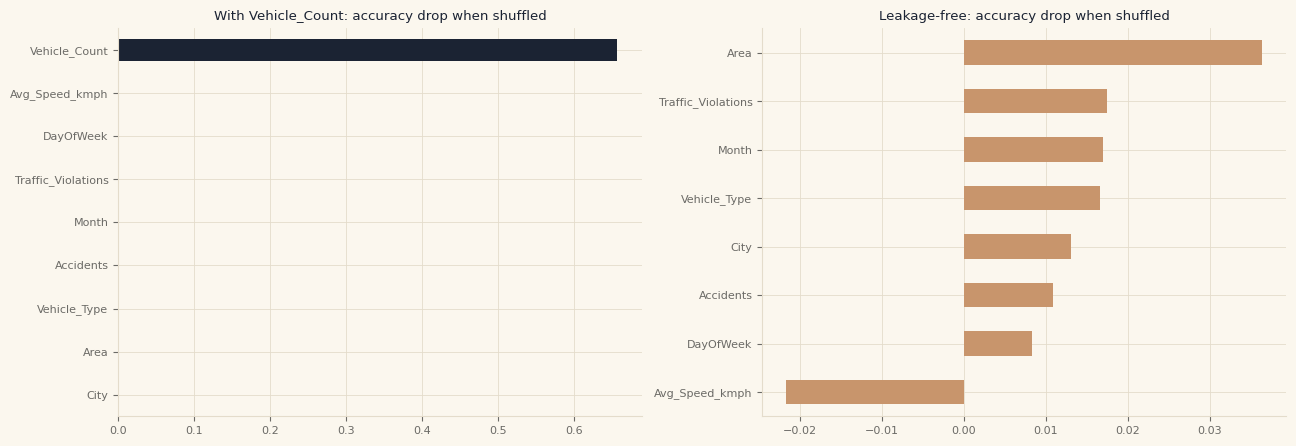

In [60]:
mname = "Random Forest"
pipe_l = make_pipe(zoo[mname], [c for c in feats_leaky if c not in cat_feats]).fit(Xtr_l, ytr)
imp = permutation_importance(pipe_l, Xte_l, yte, n_repeats=15, random_state=RANDOM_STATE, scoring="accuracy")
imp_df = pd.Series(imp.importances_mean, index=feats_leaky).sort_values()

pipe_c = make_pipe(zoo[mname], [c for c in feats_clean if c not in cat_feats]).fit(Xtr_c, ytr)
imp_c = permutation_importance(pipe_c, Xte_c, yte, n_repeats=15, random_state=RANDOM_STATE, scoring="accuracy")
imp_c_df = pd.Series(imp_c.importances_mean, index=feats_clean).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
imp_df.plot(kind="barh", ax=axes[0], color="#1B2333"); axes[0].set_title("With Vehicle_Count: accuracy drop when shuffled")
imp_c_df.plot(kind="barh", ax=axes[1], color="#C8956C"); axes[1].set_title("Leakage-free: accuracy drop when shuffled")
plt.tight_layout(); plt.show()

### B5. A sanity check: is the leakage-free model really just guessing?
We repeat the evaluation with shuffled labels. If the real model's accuracy is similar to the shuffled-label accuracy, it has learned nothing beyond chance.

In [61]:
from sklearn.model_selection import permutation_test_score
pipe = make_pipe(zoo["Random Forest"], [c for c in feats_clean if c not in cat_feats])
score, perm_scores, pval = permutation_test_score(pipe, df[feats_clean], y, cv=cv, n_permutations=50,
                                                  scoring="accuracy", random_state=RANDOM_STATE, n_jobs=-1)
print(f"Real CV accuracy (leakage-free RF): {score:.3f}")
print(f"Shuffled-label accuracy: {perm_scores.mean():.3f} +/- {perm_scores.std():.3f}")
print(f"Permutation-test p-value: {pval:.3f}  (large p => no evidence the model beats chance)")

Real CV accuracy (leakage-free RF): 0.366
Shuffled-label accuracy: 0.347 +/- 0.019
Permutation-test p-value: 0.176  (large p => no evidence the model beats chance)


## Part C: Time-specific clustering
Faculty suggestion: cluster with respect to time. The dataset has one **date** per record (no hour of day), so time can be studied at three levels: **day of week**, **month** and **season** (Winter Dec-Feb, Summer Mar-May, Monsoon Jun-Sep, Post-monsoon Oct-Nov).

We do this in three steps:
1. **C1:** test whether traffic features differ across time periods at all.
2. **C2:** cluster *time periods* (city-month profiles and individual days) and see whether the groups line up with the calendar.
3. **C3:** cluster each season separately and check whether the cluster structure changes between seasons.

In [62]:
from scipy import stats
season_of = lambda m: "Winter" if m in (12, 1, 2) else "Summer" if m in (3, 4, 5) else "Monsoon" if m in (6, 7, 8, 9) else "Post-monsoon"
df["Season"] = df["Month"].map(season_of)
df["Weekend"] = np.where(df["DayOfWeek"] >= 5, "Weekend", "Weekday")
df["DayName"] = df["Date"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

# C1: does any numeric feature differ across time periods? (one-way ANOVA, Bonferroni-corrected)
tests = []
for g in ["DayOfWeek", "Month", "Season", "Weekend"]:
    for c in num_cols:
        p = stats.f_oneway(*[x[c].values for _, x in df.groupby(g)]).pvalue
        tests.append({"Time grouping": g, "Feature": c, "p-value": p})
tests = pd.DataFrame(tests)
alpha_bonf = 0.05 / len(tests)
tests["Significant at 0.05"] = tests["p-value"] < 0.05
tests["Significant after Bonferroni"] = tests["p-value"] < alpha_bonf
print(f"{len(tests)} tests run, so the corrected threshold is {alpha_bonf:.4f}")
display(tests.round(4))

16 tests run, so the corrected threshold is 0.0031


,Time grouping,Feature,p-value,Significant at 0.05,Significant after Bonferroni
0,DayOfWeek,Vehicle_Count,0.0053,True,False
1,DayOfWeek,Avg_Speed_kmph,0.6121,False,False
2,DayOfWeek,Accidents,0.1339,False,False
3,DayOfWeek,Traffic_Violations,0.1992,False,False
4,Month,Vehicle_Count,0.9978,False,False
5,Month,Avg_Speed_kmph,0.1195,False,False
6,Month,Accidents,0.1648,False,False
7,Month,Traffic_Violations,0.2968,False,False
8,Season,Vehicle_Count,0.9717,False,False
9,Season,Avg_Speed_kmph,0.0158,True,False


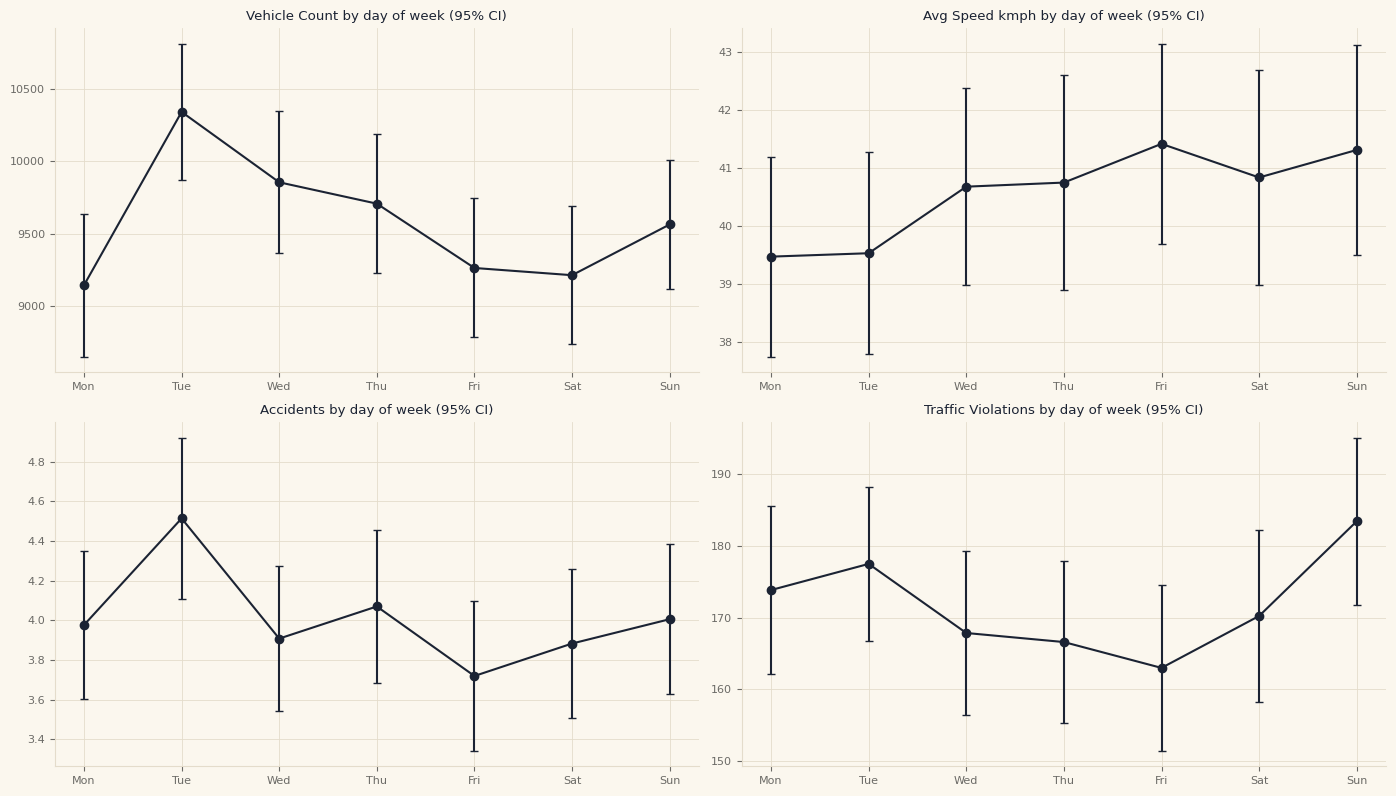

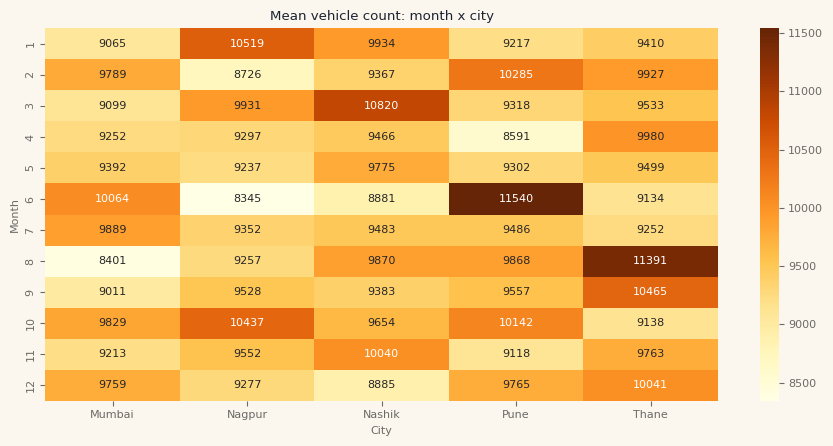

In [63]:
# Average of each feature by time period
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.ravel(), num_cols):
    m = df.groupby("DayName")[c].mean().reindex(day_order)
    sem = (df.groupby("DayName")[c].std() / np.sqrt(df.groupby("DayName")[c].size())).reindex(day_order)
    ax.errorbar(range(7), m, yerr=1.96 * sem, marker="o", color="#1B2333", capsize=3)
    ax.set_xticks(range(7)); ax.set_xticklabels([d[:3] for d in day_order]); ax.set_title(f"{c.replace('_', ' ')} by day of week (95% CI)")
plt.tight_layout(); plt.show()

monthly_city = df.pivot_table(index="Month", columns="City", values="Vehicle_Count", aggfunc="mean")
plt.figure(figsize=(9, 4.5)); sns.heatmap(monthly_city.round(0), annot=True, fmt=".0f", cmap="YlOrBr"); plt.title("Mean vehicle count: month x city"); plt.tight_layout(); plt.show()

### C2. Clustering time periods
**(a) City-month profiles.** Each (city, month) pair becomes one point (60 points) described by its mean of the four features. We cluster these and see whether clusters correspond to particular months or cities.

**(b) Daily profiles.** Each calendar date becomes one point (the mean of all records on that date), clustered with K-Means. We then test whether the daily clusters are related to the month, day of week or season using a chi-square test.

City-month silhouette by K: {2: np.float64(0.259), 3: np.float64(0.246), 4: np.float64(0.256), 5: np.float64(0.234), 6: np.float64(0.246)}
Chosen K = 2


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations
Cluster,,,,
0,9462.3,41.6,3.8,181.8
1,9799.9,38.8,4.4,155.4


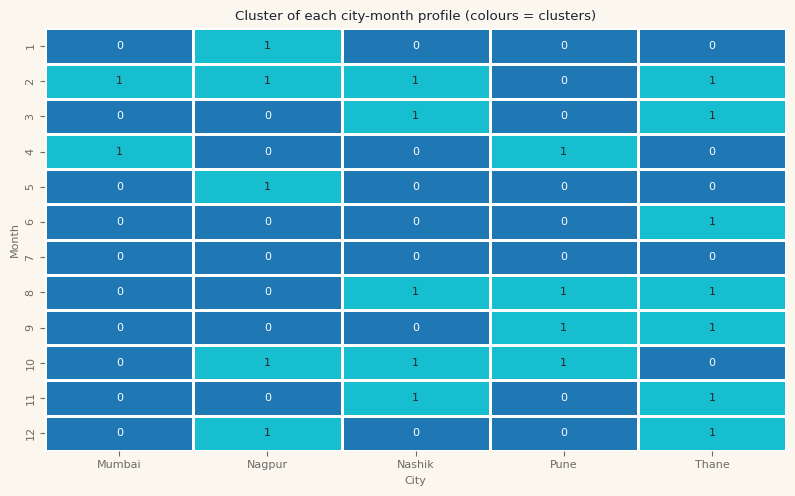

Does cluster membership depend on the month?  chi-square p = 0.449
Does cluster membership depend on the city?   chi-square p = 0.325


In [64]:
# (a) city-month profiles
cm = df.groupby(["City", "Month"])[num_cols].mean()
Zcm = StandardScaler().fit_transform(cm)
sil_cm = {k: silhouette_score(Zcm, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Zcm)) for k in range(2, 7)}
print("City-month silhouette by K:", {k: round(v, 3) for k, v in sil_cm.items()})
k_cm = max(sil_cm, key=sil_cm.get)
cm["Cluster"] = KMeans(k_cm, n_init=10, random_state=RANDOM_STATE).fit_predict(Zcm)
print(f"Chosen K = {k_cm}")
display(cm.groupby("Cluster")[num_cols].mean().round(1))

tab = cm.reset_index().pivot(index="Month", columns="City", values="Cluster")
plt.figure(figsize=(8, 5)); sns.heatmap(tab, annot=True, cmap="tab10", cbar=False, linewidths=1)
plt.title("Cluster of each city-month profile (colours = clusters)"); plt.tight_layout(); plt.show()
print("Does cluster membership depend on the month?  chi-square p =", round(stats.chi2_contingency(pd.crosstab(cm.reset_index()["Month"], cm["Cluster"].values))[1], 3))
print("Does cluster membership depend on the city?   chi-square p =", round(stats.chi2_contingency(pd.crosstab(cm.reset_index()["City"], cm["Cluster"].values))[1], 3))

Daily silhouette by K: {2: np.float64(0.174), 3: np.float64(0.182), 4: np.float64(0.202), 5: np.float64(0.205), 6: np.float64(0.195), 7: np.float64(0.205), 8: np.float64(0.201)}
Chosen K = 5


,Vehicle_Count,Avg_Speed_kmph,Accidents,Traffic_Violations,Days
DailyCluster,,,,,
0,9612.0,40.4,5.5,143.4,73
1,8702.5,33.8,4.1,198.3,81
2,10784.6,36.4,2.9,129.2,55
3,11256.0,44.3,4.3,212.6,77
4,8021.9,46.8,3.1,162.4,79


Daily cluster vs Month    : chi-square p = 0.489
Daily cluster vs DayOfWeek: chi-square p = 0.305
Daily cluster vs Season   : chi-square p = 0.280


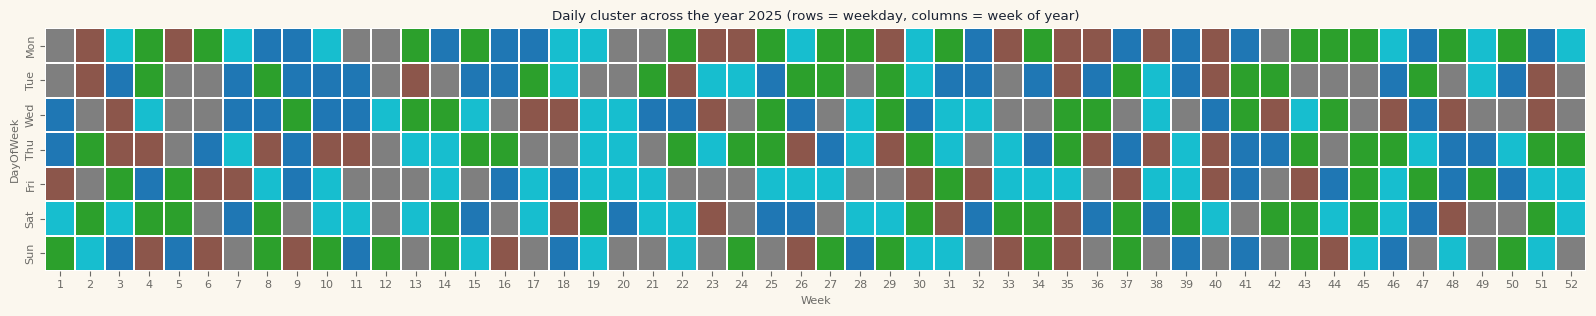

In [65]:
# (b) daily profiles
daily = df.groupby("Date")[num_cols].mean()
Zd = StandardScaler().fit_transform(daily)
sil_d = {k: silhouette_score(Zd, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Zd)) for k in range(2, 9)}
print("Daily silhouette by K:", {k: round(v, 3) for k, v in sil_d.items()})
k_d = max(sil_d, key=sil_d.get)
daily["DailyCluster"] = KMeans(k_d, n_init=10, random_state=RANDOM_STATE).fit_predict(Zd)
daily["Month"] = daily.index.month; daily["DayOfWeek"] = daily.index.dayofweek; daily["Season"] = daily["Month"].map(season_of)
print(f"Chosen K = {k_d}")
display(daily.groupby("DailyCluster")[num_cols].mean().round(1).assign(Days=daily["DailyCluster"].value_counts().sort_index()))

for col in ["Month", "DayOfWeek", "Season"]:
    p = stats.chi2_contingency(pd.crosstab(daily[col], daily["DailyCluster"]))[1]
    print(f"Daily cluster vs {col:9s}: chi-square p = {p:.3f}")

# calendar view: which cluster each day belongs to
cal_tab = daily.assign(Week=np.clip(daily.index.isocalendar().week.to_numpy().astype(int), 1, 52)).pivot_table(index="DayOfWeek", columns="Week", values="DailyCluster", aggfunc="first")
plt.figure(figsize=(16, 3.2)); sns.heatmap(cal_tab, cmap="tab10", cbar=False, yticklabels=[d[:3] for d in day_order], linewidths=.3)
plt.title("Daily cluster across the year 2025 (rows = weekday, columns = week of year)"); plt.tight_layout(); plt.show()

### C3. Cluster each season separately
If traffic behaved differently by season, the cluster structure learned inside each season would differ. We fit K-Means (K = 8, as in the main analysis) separately on each season and compare the silhouette scores and the cluster centres. A sorted-centroid comparison tells us whether the same eight "traffic types" appear in every season.

In [66]:
season_rows, centroids = [], {}
for sname in season_order:
    sub = df[df["Season"] == sname]
    Zs = StandardScaler().fit(df[num_cols]).transform(sub[num_cols])      # same scaler as the global model
    km = KMeans(8, n_init=10, random_state=RANDOM_STATE).fit(Zs)
    season_rows.append({"Season": sname, "Records": len(sub), "Silhouette (K=8)": silhouette_score(Zs, km.labels_)})
    cen = pd.DataFrame(km.cluster_centers_, columns=num_cols).sort_values("Vehicle_Count").reset_index(drop=True)
    centroids[sname] = cen
display(pd.DataFrame(season_rows).round(4))

# how far apart are corresponding clusters between seasons (distance in standardised units)?
ref = centroids["Winter"].values
dist_rows = []
for sname in season_order[1:]:
    # match clusters by optimal assignment so the comparison does not depend on cluster numbering
    from scipy.optimize import linear_sum_assignment
    D = np.linalg.norm(ref[:, None, :] - centroids[sname].values[None, :, :], axis=2)
    r, c = linear_sum_assignment(D)
    dist_rows.append({"Season vs Winter": sname, "Mean matched-centroid distance": D[r, c].mean()})
display(pd.DataFrame(dist_rows).round(3))

# baseline for "how much movement is just random sampling noise": split ONE season in two random halves
sub = df[df["Season"] == "Monsoon"].sample(frac=1, random_state=RANDOM_STATE)
halves = [sub.iloc[: len(sub) // 2], sub.iloc[len(sub) // 2:]]
cen_h = []
for h in halves:
    Zh = StandardScaler().fit(df[num_cols]).transform(h[num_cols])
    cen_h.append(KMeans(8, n_init=10, random_state=RANDOM_STATE).fit(Zh).cluster_centers_)
cen_h = [pd.DataFrame(c, columns=num_cols).sort_values("Vehicle_Count").values for c in cen_h]
D = np.linalg.norm(cen_h[0][:, None, :] - cen_h[1][None, :, :], axis=2); r, c = linear_sum_assignment(D)
print(f"Noise reference: two random halves of the SAME season differ by {D[r, c].mean():.3f}")

,Season,Records,Silhouette (K=8)
0,Winter,329,0.2300
1,Summer,322,0.2575
2,Monsoon,366,0.2335
3,Post-monsoon,183,0.2362


,Season vs Winter,Mean matched-centroid distance
0,Summer,0.914
1,Monsoon,1.191
2,Post-monsoon,1.036


Noise reference: two random halves of the SAME season differ by 1.204


### Part C summary
* **C1: no real time effect.** Of 16 tests (4 features x 4 time groupings), only two reach p < 0.05: vehicle count by day of week (p = 0.005, Tuesday is highest at about 10,300 vs 9,100-9,700 on other days) and speed by season (p = 0.016). Neither survives Bonferroni correction (threshold 0.0031), so with this many tests both are consistent with chance.
* **C2: time-based clusters are unrelated to the calendar.** City-month profiles split into two groups (silhouette 0.26), but membership does not depend on the month (p = 0.45) or the city (p = 0.33). Daily profiles give 5 clusters (silhouette about 0.2) that are unrelated to month (p = 0.49), day of week (p = 0.31) and season (p = 0.28).
* **C3: seasons do not differ.** Per-season K-Means gives silhouette 0.23-0.26, similar to the global 0.238. Matched cluster centres in other seasons are 0.91-1.19 standardised units from the winter ones, while two random halves of the *same* season are 1.20 apart. So season-to-season change is no bigger than random sampling noise.
* **Conclusion:** time-specific clustering works technically but finds no seasonal, monthly or weekly structure. With only a date (no hour), the dataset cannot show rush-hour patterns, which is the most useful kind of time-specific clustering.

## CCE V Conclusions

**Part A, Clustering**
* K-Means with K = 8 on the four numeric features is the best of the four algorithms tested, on all three metrics, and K = 8 is also the most stable choice.
* Cluster quality stays modest (silhouette 0.238) because the features are almost independent (PCA components explain about 25% of the variance each). The clusters mainly follow vehicle-count tiers and then split by speed, accidents and violations.
* City, vehicle type and calendar features did not add structure; they lowered every score.

**Part C, Time-specific clustering**
* Day-of-week, month and season were tested with ANOVA (Bonferroni-corrected), city-month and daily clustering, and per-season K-Means. No time effect survives correction, the time-based clusters are unrelated to the calendar, and seasonal cluster centres differ no more than two random halves of one season.
* The dataset records only a date, so rush-hour (time-of-day) patterns cannot be studied.

**Part B, Classification**
* `Congestion_Level` is a deterministic function of `Vehicle_Count` (non-overlapping ranges). With that feature, a depth-4 decision tree reaches about 99.9% cross-validated accuracy and 100% on the test set. This reflects the labelling rule, not learning (**target leakage**), and permutation importance shows `Vehicle_Count` is the only feature the model uses.
* Without `Vehicle_Count`, every model scores 36-38% in cross-validation, no better than the 37.4% majority-class baseline. On the held-out test set the best of them (a decision tree) gets only 32%. The permutation test (p = 0.18) finds no evidence that the leakage-free model beats chance.

**Takeaway.** This dataset supports descriptive clustering and rule-based congestion labelling, but not prediction from the remaining variables. A deployable congestion predictor would need independent signals such as time of day, weather, road capacity and incident reports.

**Future work:** collect real sensor data with **hourly timestamps** (so morning and evening peaks can be clustered), add weather and event data, and build a time-series forecaster for vehicle count itself.